# Investigation: transfer of the opco correction to the early LI-7500 years (2004-2017)

**notebook version**: `1` (30 Oct 2026)

## ℹ️ About this notebook

The CO2 flux of the open-path LI-7500 (`IRGA75`) is corrected with
[opco](https://github.com/holukas/opco) (Level 1.1). Its coefficients are fitted to the enclosed-path
LI-7200 (`IRGA72`) in the 2016-2017 overlap and applied unchanged to 2004-2015. In 2005-2009 the
correction adds about +640 gC m-2 per year. The corrected LI-7500 years agree with the LI-7200
years 2016-2025 in winter (November to March, +393 against +374 gC m-2), but have about 120 gC m-2
less uptake from May to September (-399 against -516 gC m-2). In the overlap the uncorrected LI-7500
overestimates the summer uptake by about 19 %, so a summer correction is needed.

**Question.** Is the summer daytime correction too large for the early years, for example because
the self-heating of the analyser was weaker then, or is the difference real?

The notebook checks, for the summer (May to September) unless stated otherwise:

1. **Driver support.** Whether the drivers of the model in the early years lie within the range of
   the training data.
2. **The correction against its drivers.** Whether the early years receive a larger correction
   than the training years under the same conditions, and which input causes a difference.
3. **The flux under matched conditions.** Daytime `NEE` standardised to a common distribution of
   light and air temperature, per year, for the uncorrected and the corrected LI-7500 flux and for
   the LI-7200 flux. Nighttime `NEE` in the same way.
4. **Tests of the self-heating from the LI-7500 alone.** The transfer of the model between the two
   training years; the dependence of the summer daytime flux on wind speed at the same light and
   temperature, which carries the signature of the self-heating; and the contrast between sunny
   days and nights in winter, where photosynthesis is small and the self-heating is largest.
5. **Instrument and setup history** from the documentation, the GIN fieldbook and the data.
6. **Weather and footprint** of the early summers.
7. **Implied adjustment.** The change of the May-September sum under two scenarios, one based on
   the wind-speed test of section 4, one on the assumption that the ecosystem did not change.

The notebook writes no file. It reads the outputs of the chain; no input is changed.

### What is evidence and what is assumption

- The matched-condition comparisons (section 3) are measurements. They show *where* the early
  years differ, not *why*: flux data alone cannot separate a smaller instrument error from a real
  change of the ecosystem.
- The wind-speed test (section 4) assumes that, at the same light and temperature, the ecosystem
  flux depends on wind speed in the same way in every year. The year-to-year spread of this
  dependence in the LI-7200 years sets its uncertainty.
- The winter test (section 4) assumes that a change of the self-heating of the analyser acts in
  winter as in summer. It is the same heating term in the model, scaled by the same coefficient.
- Scenario B (section 7) assumes that the ecosystem responded to light and temperature in
  2005-2009 as in 2016-2025. It is an upper bound for the effect of an oversized correction, not an
  estimate.

### Known limitations

- **No measured light before September 2004 (PPFD) and September 2005 (SW_IN).** The comparisons
  under matched light use measured PPFD and start in 2005. 2004 is shown only where light is not
  needed. The opco model itself used the gap-filled SW_IN, which is modelled for 2004 and most of
  2005.
- **The light sensors are not perfectly stable.** The SW_IN radiometer reads about 3 % high from
  2013, the PPFD sensor about 3 to 7 % low from 2022 (see the meteo pages). At high light this
  changes matched-light comparisons by a few tenths of a µmol m-2 s-1.
- **The reference years have their own weather.** The LI-7200 years 2016-2025 include the dry
  summers of 2018 and 2022. Their year-to-year spread is shown with them.
- **Section 4 uses an approximate training set.** It selects the training half-hours from the
  Level-3.2 flags of both `05` notebooks instead of rerunning Levels 2 to 3.2 as `01` does. Its
  models reproduce the stored correction to about 0.1 µmol m-2 s-1 in summer daytime.
- **The `IRGA75` `05` output** comes from a run with stricter tests of negative nighttime values.
  This changes nights only; the summer daytime records are not affected.

***

## 📇 Data sources

All files are read from the external data folder, by absolute path, and indexed on
`TIMESTAMP_MIDDLE`.

- `30_FLUX_POST-PROCESSING_CHAIN/IRGA75/01_FPPC_IRGA75_INPUT_OPCO_2004-2017_2019.parquet`: the
  uncorrected LI-7500 flux `FC`, the corrected flux `FC_L1.1_OPCO = FC - BIAS_OPCO`, the bias, its
  parts, the coefficients and the drivers of opco.
- `30_FLUX_POST-PROCESSING_CHAIN/IRGA75/05_FPPC_IRGA75_NEE_OPCO_2004-2017.parquet`: the corrected
  `NEE` after the quality tests (`NEE_L3.1_L3.3_CUT_50_QCF`).
- `30_FLUX_POST-PROCESSING_CHAIN/IRGA72/05_FPPC_IRGA72_NEE_2016-2026.09.parquet` and its input
  `00_FPPC_IRGA72_INPUT_2016-2026.09.parquet`: the LI-7200 `NEE`, `FC`, `H`, `LE`, u* and the flow
  rate.
- `10_METEO/30_PRODUCTS/99_METEO_MERGED_2004-2026.09.parquet`: the meteo products, with their
  flags of measured values. Light, air temperature, VPD and soil water content are taken from here
  for both analysers, so the two are binned on the same series.

**The uncorrected `NEE`** is the corrected `NEE` plus `BIAS_OPCO` on the same records:
`NEE_L3.1 = FC_L1.1_OPCO + storage` and `FC_L1.1_OPCO = FC - BIAS_OPCO`, so this is `FC` plus the
same storage term, on the records that pass all tests. The load cell verifies both identities.

## ⚙️ Settings

In [1]:
# --- Sources -----------------------------------------------------------------------------------
DATADIR = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow")
OPCOFILE = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN\IRGA75\01_FPPC_IRGA75_INPUT_OPCO_2004-2017_2019.parquet"
NEE75FILE = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN\IRGA75\05_FPPC_IRGA75_NEE_OPCO_2004-2017.parquet"
NEE72FILE = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN\IRGA72\05_FPPC_IRGA72_NEE_2016-2026.09.parquet"
IN72FILE = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN\IRGA72\00_FPPC_IRGA72_INPUT_2016-2026.09.parquet"
METEOFILE = rf"{DATADIR}\10_METEO\30_PRODUCTS\99_METEO_MERGED_2004-2026.09.parquet"

# --- Columns -----------------------------------------------------------------------------------
NEE_COL = 'NEE_L3.1_L3.3_CUT_50_QCF'   # NEE after all tests of the chain (u* threshold CUT_50)
NEE_L32_COL = 'NEE_L3.1_L3.2_QCF'      # NEE after Level 3.2, no u* filter (training selection)
TA_OPCO = 'TA_T1_47_1_HOMOGENIZED_gfXG'  # the air temperature opco used
SW_OPCO = 'SW_IN_T1_47_1_gfXG'           # the SW_IN opco used (modelled before September 2005)
FLOW_COL, FLOW_MIN = 'CUSTOM_FLOW_VOLRATE_MEAN', 8  # LI-7200 flow rate (l min-1), as in 01
# Meteo products and the short names used here. A flag of 0 marks a measured value.
METEO_COLS = {'SW_IN_T1_47_1_gfXG': 'sw', 'FLAG_SW_IN_T1_47_1_ISFILLED': 'sw_flag',
              'TA_T1_47_1_HOMOGENIZED_gfXG': 'ta', 'PPFD_IN_T1_47_1_gfXG': 'ppfd',
              'FLAG_PPFD_IN_T1_47_1_ISFILLED': 'ppfd_flag', 'VPD_T1_47_1_HOMOGENIZED': 'vpd',
              'SWC_FF1_0.1_1_HOMOGENIZED': 'swc10', 'SWC_FF1_0.3_1_HOMOGENIZED': 'swc30',
              'SW_OUT_T1_47_1': 'sw_out', 'LW_IN_T1_47_1': 'lw_in', 'LW_OUT_T1_47_1': 'lw_out'}

# --- Periods -----------------------------------------------------------------------------------
SUMMER = (5, 6, 7, 8, 9)
WINTER = (11, 12, 1, 2)
IRGA75_LAST = '2017-12-31 23:45:00'   # the 2019 stand-in run is left out
IRGA72_LAST = '2025-12-31 23:45:00'   # 2026 is incomplete
PERIODS_75 = {'2005-2009': (2005, 2009), '2010-2015': (2010, 2015), '2016-2017': (2016, 2017)}
PERIODS_72 = {'2016-2017': (2016, 2017), '2018-2025': (2018, 2025)}
EARLY = (2005, 2009)
TRAIN = (2016, 2017)
FIRST_LIGHT_YEAR = 2005   # first summer with measured PPFD

# --- Matched conditions ------------------------------------------------------------------------
DAY_SW = 12        # W m-2, the day flag of opco
DAY_PPFD = 20      # umol m-2 s-1: daytime in the matched-light comparisons (measured PPFD above it)
PPFD_BINS = [20, 200, 400, 600, 800, 1000, 1200, 1500, 2500]   # umol m-2 s-1
TA_BINS = [-10, 10, 14, 18, 22, 26, 40]                         # degC, summer daytime
NIGHT_TA_BINS = [-5, 8, 10, 12, 14, 16, 18, 20, 22, 35]          # degC, summer nighttime
MIN_CELL_N = 10    # fewest records for a cell mean to enter a standardised mean
DRIVER_BINS = {'TA': [8, 12, 16, 20, 24, 28, 34], 'SW_IN': [12, 100, 200, 300, 400, 500, 600, 700, 800, 1100],
               'USTAR': [0.3, 0.45, 0.6, 0.8, 1.0, 1.5]}   # u* below 0.3 is removed by the u* filter
WS_BINS = [0, 1, 1.5, 2, 2.5, 3, 4, 6]

# --- Winter test -------------------------------------------------------------------------------
WINTER_TA = (-8, 5)                 # degC: cold half-hours of November to February
WINTER_TA_BINS = [-8, -3, 0, 2, 5]
SUNNY_SW = 150                      # W m-2: sunny half-hour
WINTER_MIN_SUNNY, WINTER_MIN_NIGHT = 15, 30   # fewest records per month unit
# Month units of each group of winters: before and after the recalibration of December 2007, and
# the training period.
WINTER_GROUPS = {'winters 2004/05-2006/07': ('2004-11-01', '2007-03-01'),
                 'winters 2007/08-2008/09': ('2007-11-01', '2009-03-01'),
                 'training winters': ('2016-01-01', '2018-01-01')}

# --- Summer wind-speed test --------------------------------------------------------------------
WIND_LOW = 1.5               # m s-1: low wind speed, at or below
WIND_HIGH = (2.5, 5.0)       # m s-1: high wind speed, above the first and at or below the second
WIND_PPFD_BINS = [200, 400, 600, 800, 1000, 1200, 1500, 2500]   # umol m-2 s-1, light above 200 only
WIND_REF_YEARS = (2010, 2017)   # LI-7500 years whose wind signature serves as reference (s = 1)
WIND_GROUPS = {'2005-2007': (2005, 2007), '2008-2009': (2008, 2009), '2010-2015': (2010, 2015),
               '2016-2017': (2016, 2017)}

# --- opco refits (section 4) -------------------------------------------------------------------
FEATURES_XI = ('ta', 'sw_in', 'ustar', 'u', 'isday')   # as in 01
FEATURES_K = FEATURES_XI + ('k_op',)

# --- Instrument history ------------------------------------------------------------------------
# Maintenance of the LI-7500 recorded in the GIN fieldbook (external data folder,
# fieldbook_gin/CH-LAE_fieldbook_redacted_until_2025.md). The same head, 75H-0640, is named in
# the entries of 2011 and 2016; the setup table of Yearly_Notes.md lists one LI-7500 (IRGA75-A)
# for 2004-2017.
FIELDBOOK_LI7500 = {
    '2007-09-26': 'chemicals replaced, calibrated',
    '2007-12-19': 'calibration',
    '2008-05-16': 'calibration',
    '2010-12-16': 'reference and calibration; head re-fastened with steel wire',
    '2011-05-10': 'reference, chemicals replaced, calibration',
    '2013-11-01': 'reference, chemicals replaced',
    '2016-01-14': 'reference, chemicals replaced, lab calibration',
}

# umol CO2 m-2 s-1 over one half-hour, in gC m-2
GC_PER_HALFHOUR = 12.011e-6 * 1800

## 📦 Imports

In [2]:
from datetime import datetime
import importlib.metadata
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor

from diive.core.plotting.styles import chainplots as cp
from opco.physmodel import PhysBiasModel

pd.set_option('display.max_rows', 60)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)


def tabcap(text, width=100):
    """Print a table caption, above the table it belongs to."""
    print(textwrap.fill(f"Table - {text}", width) + "\n")


def figcap(fig, text, width=150):
    """Place a caption under a figure drawn with a layout engine. Call after the last axes."""
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    fig.supxlabel(textwrap.fill(f"Figure - {text}", width), fontsize=9, ha='left', x=0.005)


NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
for _p in ('diive', 'opco', 'scikit-learn'):
    print(f"{_p} version: v{importlib.metadata.version(_p)}")

Last run: 2026-10-30 19:30:09
diive version: v0.93.0
opco version: v0.1.0
scikit-learn version: v1.8.0


## 📂 Load

In [3]:
_c75 = ['FC', 'FC_L1.1_OPCO', 'BIAS_OPCO', 'BIAS_HEAT_OPCO', 'BIAS_WPL_H_OPCO', 'HEAT_OPCO', 'WPL_H_OPCO',
        'XI_OPCO', 'K_OPCO', 'K_OP_OPCO', 'OUT_OF_ENVELOPE_OPCO', 'USTAR', 'WS', 'WD', 'H', 'LE',
        'CO2_MOLAR_DENSITY', 'CO2_MIXING_RATIO', 'H_SSITC_TEST', 'LE_SSITC_TEST', 'W_SIGMA', TA_OPCO, SW_OPCO]
_c72 = ['FC', 'USTAR', 'WS', 'WD', 'H', 'LE', 'H_SSITC_TEST', 'LE_SSITC_TEST', 'W_SIGMA', FLOW_COL]
_cnee = [NEE_COL, NEE_L32_COL, 'NEE_L3.1', 'SC_SINGLE_gfRMED_L3.1']

o75 = pd.read_parquet(OPCOFILE, columns=_c75).loc[:IRGA75_LAST]
n75 = pd.read_parquet(NEE75FILE, columns=_cnee).loc[:IRGA75_LAST]
i72 = pd.read_parquet(IN72FILE, columns=_c72).loc[:IRGA72_LAST]
n72 = pd.read_parquet(NEE72FILE, columns=_cnee).loc[:IRGA72_LAST]
met = pd.read_parquet(METEOFILE, columns=list(METEO_COLS)).rename(columns=METEO_COLS)

for _name, _d in [('opco', o75), ('IRGA75 NEE', n75), ('IRGA72 input', i72), ('IRGA72 NEE', n72), ('meteo', met)]:
    _steps = _d.index.to_series().diff().dropna().unique()
    assert _d.index.name == 'TIMESTAMP_MIDDLE' and not _d.index.duplicated().any(), _name
    assert len(_steps) == 1 and _steps[0] == pd.Timedelta('30min'), f"{_name} is not on a continuous 30MIN index"
    print(f"{_name:<13} {len(_d):>8,} records  {_d.index[0]} -> {_d.index[-1]}")
assert o75.index.equals(n75.index) and i72.index.equals(n72.index)
assert met.index[0] <= o75.index[0] and met.index[-1] >= n72.index[-1], "meteo does not cover the fluxes"

# The two identities behind the uncorrected NEE (see Data sources).
_ok = o75['FC_L1.1_OPCO'].notna()
assert np.allclose(o75.loc[_ok, 'FC_L1.1_OPCO'], o75.loc[_ok, 'FC'] - o75.loc[_ok, 'BIAS_OPCO'])
_ok = n75['NEE_L3.1'].notna()
assert np.allclose(n75.loc[_ok, 'NEE_L3.1'],
                   o75.loc[_ok, 'FC_L1.1_OPCO'] + n75.loc[_ok, 'SC_SINGLE_gfRMED_L3.1'])
assert n75[NEE_COL].dropna().index.isin(o75['BIAS_OPCO'].dropna().index).all()
print("\nNEE_L3.1 = FC - BIAS_OPCO + storage verified on all IRGA75 records")

opco           245,472 records  2004-01-01 00:15:00 -> 2017-12-31 23:45:00
IRGA75 NEE     245,472 records  2004-01-01 00:15:00 -> 2017-12-31 23:45:00
IRGA72 input   175,344 records  2016-01-01 00:15:00 -> 2025-12-31 23:45:00
IRGA72 NEE     175,344 records  2016-01-01 00:15:00 -> 2025-12-31 23:45:00
meteo          398,832 records  2004-01-01 00:15:00 -> 2026-09-30 23:45:00

NEE_L3.1 = FC - BIAS_OPCO + storage verified on all IRGA75 records


In [4]:
# One frame per analyser, joined with the meteo products.
met['ppfd_meas'] = met['ppfd_flag'] == 0
met['sw_meas'] = met['sw_flag'] == 0
met['rn'] = met['sw'] - met['sw_out'] + met['lw_in'] - met['lw_out']
A = o75.join(n75).join(met)
B = i72.join(n72).join(met)
A['UNC'] = A[NEE_COL] + A['BIAS_OPCO']   # uncorrected NEE on the records that pass all tests
for _d in (A, B):
    _d['year'] = _d.index.year
    _d['summer'] = _d.index.month.isin(SUMMER)
    _d['ust_u'] = _d['USTAR'] / _d['WS']


def period_of(years, periods):
    """Label of the period each year falls in, or None."""
    out = pd.Series(None, index=years.index if hasattr(years, 'index') else None, dtype=object)
    for _label, (_y0, _y1) in periods.items():
        out[(years >= _y0) & (years <= _y1)] = _label
    return out


A['period'] = period_of(A['year'], PERIODS_75)
B['period'] = period_of(B['year'], PERIODS_72)

# Long table of the four series compared in section 3: one row per record and series.
Q75 = A[NEE_COL].notna()
Q72 = B[NEE_COL].notna()
_parts = [('IRGA75 uncorrected', A.loc[Q75, 'UNC'], A.loc[Q75, 'period']),
          ('IRGA75 corrected', A.loc[Q75, NEE_COL], A.loc[Q75, 'period']),
          ('opco bias', A.loc[Q75, 'BIAS_OPCO'], A.loc[Q75, 'period']),
          ('IRGA72', B.loc[Q72, NEE_COL], B.loc[Q72, 'period'])]
L = pd.concat([pd.DataFrame({'series': _s, 'value': _v, 'period': _p}) for _s, _v, _p in _parts]).join(met)
L['year'] = L.index.year
L['month'] = L.index.month
L['doy'] = L.index.dayofyear
L['summer'] = L['month'].isin(SUMMER)
SERIES_75 = ['IRGA75 uncorrected', 'IRGA75 corrected']
print(L.groupby('series').size().rename('records').to_frame().T)

series   IRGA72  IRGA75 corrected  IRGA75 uncorrected  opco bias
records   80373             93226               93226      93226


In [5]:
# Colours: one per IRGA75 period, the IRGA72 periods in ink (solid and dashed).
P75_COLORS = {'2005-2009': cp.TEST_COLORS[1], '2010-2015': cp.TEST_COLORS[2], '2016-2017': cp.TEST_COLORS[3]}
P72_STYLE = {'2016-2017': '-', '2018-2025': '--'}
SERIES_COLORS = {'IRGA75 uncorrected': cp.REJECTED, 'IRGA75 corrected': cp.CLEANED, 'IRGA72': cp.INK,
                 'opco bias': cp.TEST_COLORS[5]}


def bin_labels(edges):
    """Short labels for the intervals between consecutive edges."""
    return [f"{a:g}-{b:g}" for a, b in zip(edges[:-1], edges[1:])]


def cells(d, xcol, xbins, ycol, ybins):
    """Bin keys of two drivers, for groupby."""
    return [pd.cut(d[xcol], xbins), pd.cut(d[ycol], ybins)]


def std_mean(d, weights, keys, col='value'):
    """Mean of col over cells, weighted by a fixed cell distribution; cells with too few records drop out.

    Returns the standardised mean, the share of the weight that is covered, and the record count.
    """
    g = d.groupby(keys, observed=True)[col]
    m = g.mean()[g.size() >= MIN_CELL_N]
    w = weights.reindex(m.index).fillna(0)
    cover = w.sum()
    return pd.Series({'mean': (m * w).sum() / cover if cover > 0 else np.nan, 'cover': cover, 'n': len(d)})


# The fixed distributions: all summer half-hours of 2005-2025 with measured PPFD (day) and all
# summer nights of 2005-2025, whether or not a flux was measured. A standardised mean is thus what
# a year would show under the light and temperature of an average summer.
_m = met.loc[f'{FIRST_LIGHT_YEAR}':IRGA72_LAST]
_mday = _m[_m.index.month.isin(SUMMER) & _m['ppfd_meas'] & (_m['ppfd'] > DAY_PPFD)]
W_DAY = _mday.groupby(cells(_mday, 'ppfd', PPFD_BINS, 'ta', TA_BINS), observed=True).size()
W_DAY = W_DAY / W_DAY.sum()
_mnight = _m[_m.index.month.isin(SUMMER) & (_m['sw'] <= 0)]
W_NIGHT = _mnight.groupby(pd.cut(_mnight['ta'], NIGHT_TA_BINS), observed=True).size()
W_NIGHT = W_NIGHT / W_NIGHT.sum()
print(f"day cells: {len(W_DAY)}, night cells: {len(W_NIGHT)}")

day cells: 48, night cells: 9


## 🧮 1 Driver support in summer daytime

The drivers of ξ and k are air temperature, SW_IN, u*, wind speed, the day flag and, for k, the
weekly detector `k_op`. The heating term itself is computed from air temperature, u*, wind speed,
pressure and the CO2 and H2O densities of the LI-7500. Shown are the summer daytime half-hours
(SW_IN above 12 W m-2, the day flag of opco) that pass all tests, per period.

In [6]:
DRV = {TA_OPCO: 'air temperature (degC)', SW_OPCO: 'SW_IN (W m-2)', 'USTAR': 'u* (m s-1)',
       'WS': 'wind speed (m s-1)', 'ust_u': 'u* / wind speed (-)', 'H': 'H (W m-2)',
       'CO2_MOLAR_DENSITY': 'CO2 density (mmol m-3)', 'K_OP_OPCO': 'k_op (-)'}
SD = A[A['summer'] & (A[SW_OPCO] > DAY_SW) & Q75 & A['period'].notna()].copy()
print(SD.groupby('period').size().rename('summer daytime records').to_frame().T)

period                  2005-2009  2010-2015  2016-2017
summer daytime records      11618      13192       4858


### 📊 Plot: distributions of the drivers in summer daytime, per period

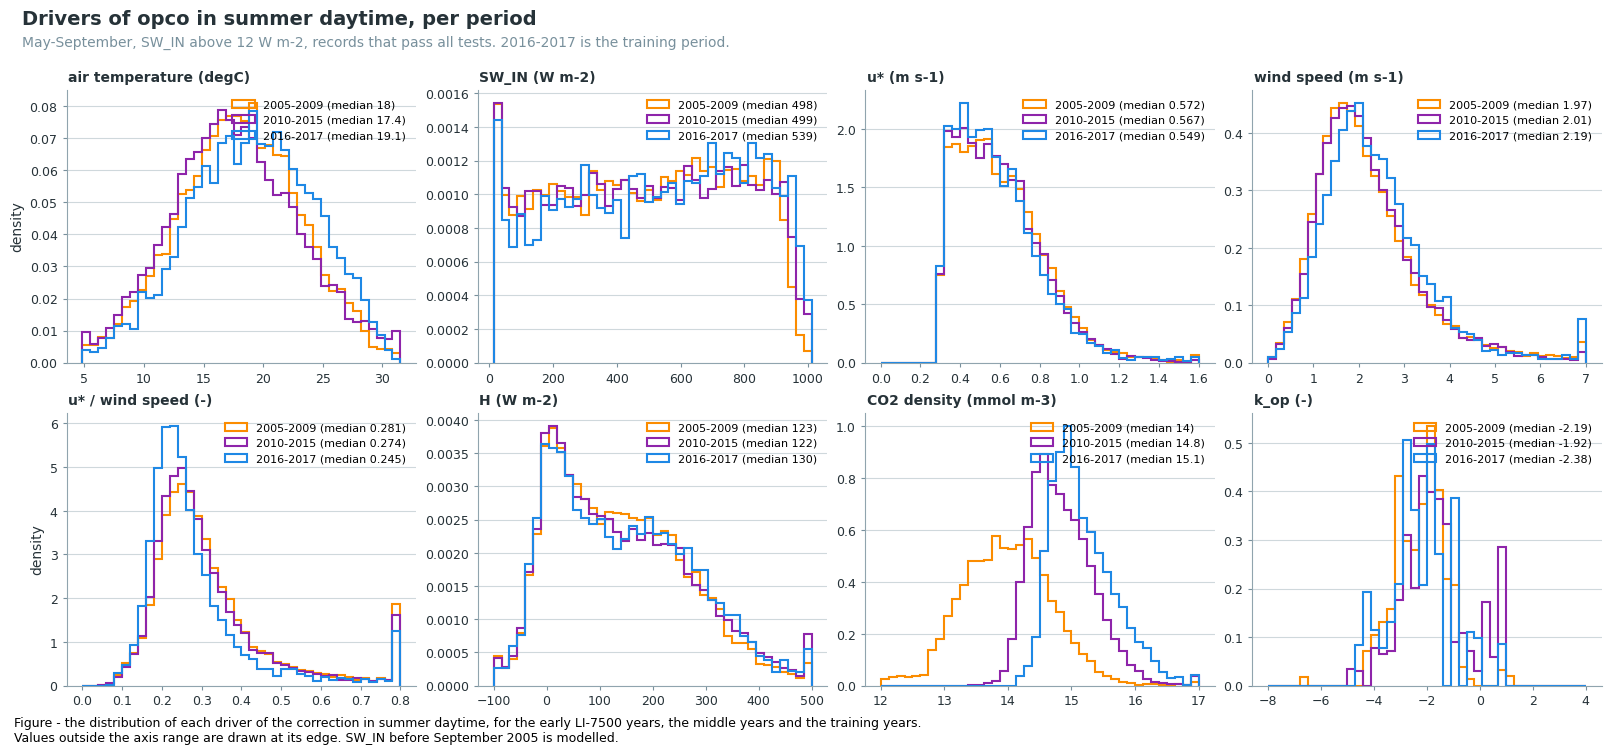

In [7]:
_lims = {'USTAR': (0, 1.6), 'WS': (0, 7), 'ust_u': (0, 0.8), 'H': (-100, 500), 'K_OP_OPCO': (-8, 4),
         'CO2_MOLAR_DENSITY': (12, 17)}
fig, axs = plt.subplots(2, 4, figsize=(16, 7.5), layout='constrained')
for _ax, (_c, _label) in zip(axs.flat, DRV.items()):
    _lo, _hi = _lims.get(_c, (SD[_c].quantile(0.002), SD[_c].quantile(0.998)))
    _edges = np.linspace(_lo, _hi, 41)
    for _p, _color in P75_COLORS.items():
        _x = SD.loc[SD['period'] == _p, _c].dropna()
        _ax.hist(_x.clip(_lo, _hi), bins=_edges, density=True, histtype='step', color=_color, linewidth=1.5,
                 label=f"{_p} (median {_x.median():.3g})")
    cp.style_axes(_ax)
    cp.panel_label(_ax, _label)
    _ax.legend(frameon=False, fontsize=8, loc='upper right')
axs[0, 0].set_ylabel('density')
axs[1, 0].set_ylabel('density')
cp.figure_title(fig, 'Drivers of opco in summer daytime, per period',
                'May-September, SW_IN above 12 W m-2, records that pass all tests. 2016-2017 is the training period.')
figcap(fig, "the distribution of each driver of the correction in summer daytime, for the early LI-7500 years, "
            "the middle years and the training years. Values outside the axis range are drawn at its edge. "
            "SW_IN before September 2005 is modelled.")
plt.show()

### 📋 Table: driver medians and share outside the training range, summer daytime

In [8]:
_tr = SD[SD['period'] == '2016-2017']
_rows = {}
for _p, _g in SD.groupby('period'):
    _r = {f'median {k}': _g[k].median() for k in DRV}
    for _k in (TA_OPCO, SW_OPCO, 'USTAR', 'WS', 'WPL_H_OPCO'):
        _lo, _hi = _tr[_k].quantile([0.001, 0.999])
        _r[f'outside % {_k}'] = 100 * ((_g[_k] < _lo) | (_g[_k] > _hi)).mean()
    _r['OUT_OF_ENVELOPE_OPCO %'] = 100 * _g['OUT_OF_ENVELOPE_OPCO'].mean()
    _rows[_p] = _r
DRIVER_TAB = pd.DataFrame(_rows)
tabcap("per period, the median of each driver over the summer daytime records, the share of records outside "
       "the 0.1 to 99.9 % range of the summer daytime records of 2016-2017, and the share flagged by "
       "opco as outside its training envelope (TA, u* or the WPL thermal term outside the range of all "
       "training half-hours)")
display(DRIVER_TAB.round(3))

Table - per period, the median of each driver over the summer daytime records, the share of records
outside the 0.1 to 99.9 % range of the summer daytime records of 2016-2017, and the share flagged by
opco as outside its training envelope (TA, u* or the WPL thermal term outside the range of all
training half-hours)



,2005-2009,2010-2015,2016-2017
median TA_T1_47_1_HOMOGENIZED_gfXG,18.010,17.425,19.129
median SW_IN_T1_47_1_gfXG,498.235,498.586,539.397
median USTAR,0.572,0.567,0.549
median WS,1.974,2.011,2.192
median ust_u,0.281,0.274,0.245
median H,123.054,121.638,129.756
median CO2_MOLAR_DENSITY,13.988,14.791,15.070
median K_OP_OPCO,-2.189,-1.918,-2.378
outside % TA_T1_47_1_HOMOGENIZED_gfXG,0.405,1.076,0.206
outside % SW_IN_T1_47_1_gfXG,0.060,0.265,0.206


### 📊 Plot: u* relative to wind speed, by wind-speed class and year

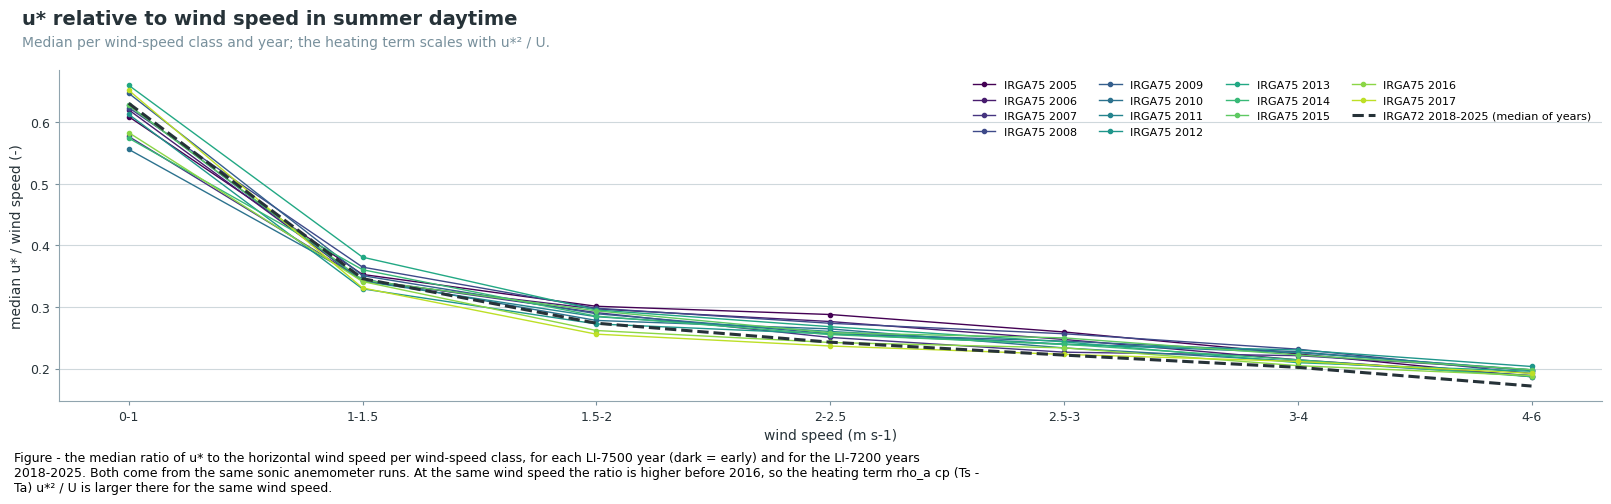

In [9]:
_nb = len(WS_BINS) - 1
_g = (SD.groupby(['year', pd.cut(SD['WS'], WS_BINS, labels=False)])['ust_u'].median().unstack()
      .reindex(columns=range(_nb)))
_g72 = B[B['summer'] & (B['sw'] > DAY_SW) & Q72]
_g72 = (_g72.groupby(['year', pd.cut(_g72['WS'], WS_BINS, labels=False)])['ust_u'].median().unstack()
        .reindex(columns=range(_nb)))
fig, ax = plt.subplots(figsize=(16, 5), layout='constrained')
_x = np.arange(len(WS_BINS) - 1)
_years = sorted(SD['year'].unique())
_shades = plt.get_cmap('viridis')(np.linspace(0, 0.9, len(_years)))
for _y, _color in zip(_years, _shades):
    ax.plot(_x, _g.loc[_y].to_numpy(), color=_color, marker='o', markersize=3, linewidth=1,
            label=f"IRGA75 {_y}")
ax.plot(_x, _g72.loc[2018:2025].median().to_numpy(), color=cp.INK, linewidth=2.2, linestyle='--',
        label='IRGA72 2018-2025 (median of years)')
ax.set_xticks(_x, bin_labels(WS_BINS))
ax.set_xlabel('wind speed (m s-1)')
ax.set_ylabel('median u* / wind speed (-)')
cp.style_axes(ax)
ax.legend(frameon=False, fontsize=8, loc='upper right', ncol=4)
cp.figure_title(fig, 'u* relative to wind speed in summer daytime',
                'Median per wind-speed class and year; the heating term scales with u*² / U.')
figcap(fig, "the median ratio of u* to the horizontal wind speed per wind-speed class, for each LI-7500 year "
            "(dark = early) and for the LI-7200 years 2018-2025. Both come from the same sonic anemometer "
            "runs. At the same wind speed the ratio is higher before 2016, so the heating term "
            "rho_a cp (Ts - Ta) u*² / U is larger there for the same wind speed.")
plt.show()

## 🔬 2 The correction against its drivers

The bias, its heating part, the heating term and the coefficient ξ per class of air temperature,
SW_IN and u*, for summer daytime. If the early years received a larger correction than the training
years under the same conditions, the curves of 2005-2009 would lie below those of 2016-2017.

### 📊 Plot: correction and its parts by air temperature, SW_IN and u*, summer daytime

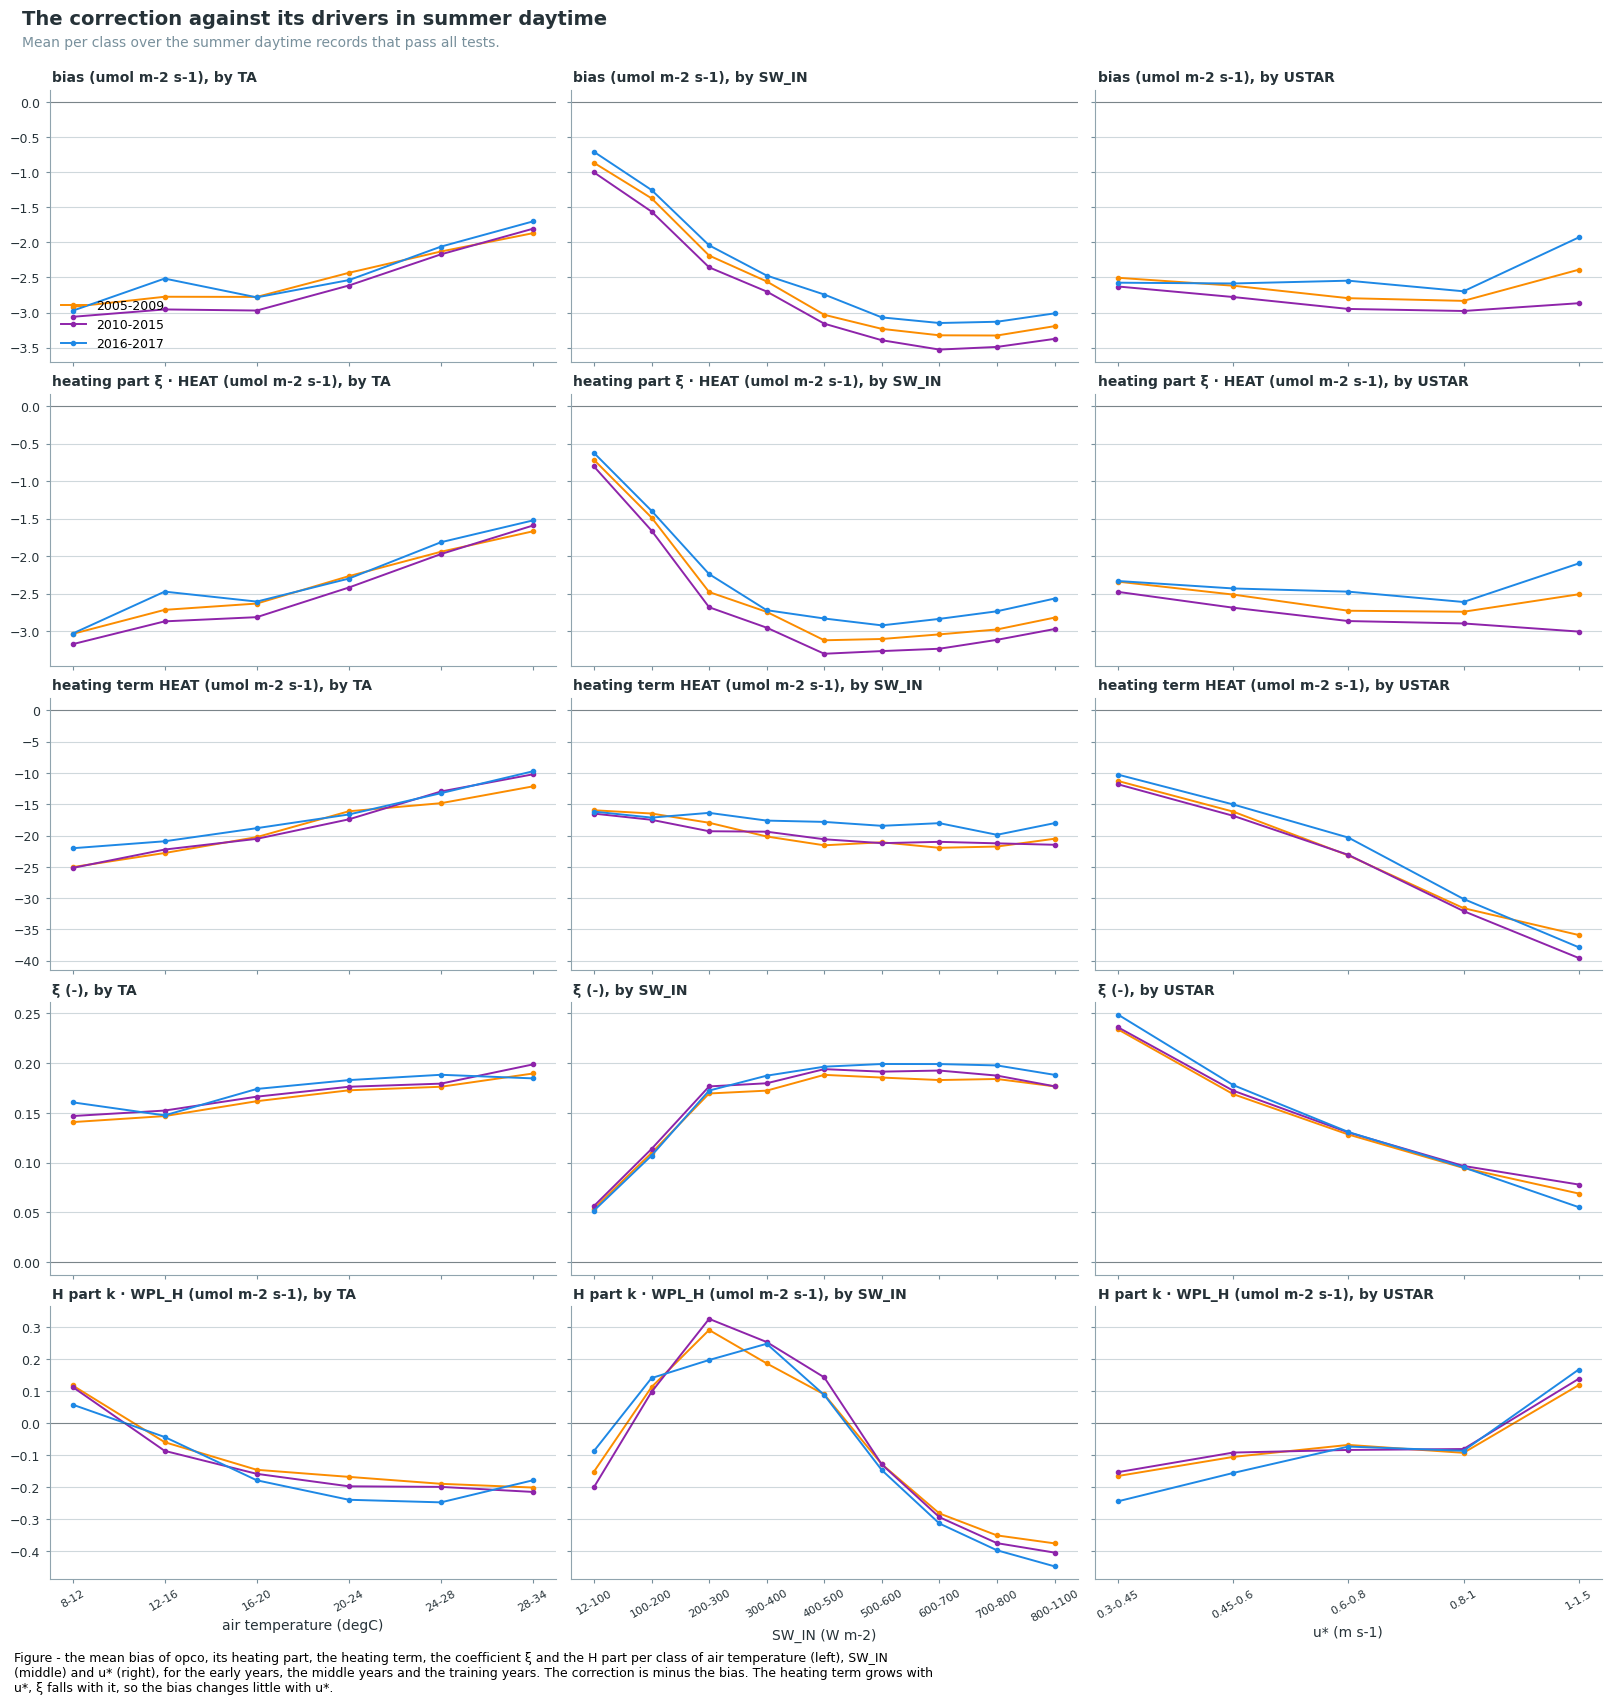

In [10]:
_rows_plot = [('BIAS_OPCO', 'bias (umol m-2 s-1)'), ('BIAS_HEAT_OPCO', 'heating part ξ · HEAT (umol m-2 s-1)'),
              ('HEAT_OPCO', 'heating term HEAT (umol m-2 s-1)'), ('XI_OPCO', 'ξ (-)'),
              ('BIAS_WPL_H_OPCO', 'H part k · WPL_H (umol m-2 s-1)')]
_drv = {'TA': TA_OPCO, 'SW_IN': SW_OPCO, 'USTAR': 'USTAR'}
fig, axs = plt.subplots(len(_rows_plot), 3, figsize=(16, 17), sharex='col', sharey='row', layout='constrained')
for _j, (_dname, _dcol) in enumerate(_drv.items()):
    _edges = DRIVER_BINS[_dname]
    _xc = np.arange(len(_edges) - 1)
    for _p, _color in P75_COLORS.items():
        _g = SD[SD['period'] == _p]
        _grp = _g.groupby(pd.cut(_g[_dcol], _edges), observed=False)
        _n = _grp.size()
        for _i, (_col, _title) in enumerate(_rows_plot):
            _m = _grp[_col].mean().where(_n >= MIN_CELL_N).to_numpy()
            axs[_i, _j].plot(_xc, _m, color=_color, marker='o', markersize=3, linewidth=1.4, label=_p)
    for _i, (_col, _title) in enumerate(_rows_plot):
        _ax = axs[_i, _j]
        _ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
        cp.style_axes(_ax)
        cp.panel_label(_ax, f"{_title}, by {_dname}")
    axs[-1, _j].set_xticks(_xc, bin_labels(_edges), fontsize=8, rotation=30)
    axs[-1, _j].set_xlabel({'TA': 'air temperature (degC)', 'SW_IN': 'SW_IN (W m-2)', 'USTAR': 'u* (m s-1)'}[_dname])
axs[0, 0].legend(frameon=False, fontsize=9, loc='lower left')
cp.figure_title(fig, 'The correction against its drivers in summer daytime',
                'Mean per class over the summer daytime records that pass all tests.')
figcap(fig, "the mean bias of opco, its heating part, the heating term, the coefficient ξ and the H part per class of "
            "air temperature (left), SW_IN (middle) and u* (right), for the early years, the middle years and the "
            "training years. The correction is minus the bias. The heating term grows with u*, ξ falls with it, "
            "so the bias changes little with u*.")
plt.show()

### 📋 Table: correction under matched light and temperature, summer daytime

Each column is standardised to the same distribution of measured PPFD and air temperature (the
summer daytime half-hours of 2005-2025, see the load section), so the periods differ only by what
the model does under the same conditions, not by their weather. The last column of each part gives
the ratio of the early to the training period.

In [11]:
_sd = SD[SD['ppfd_meas'] & (SD['ppfd'] > DAY_PPFD)].copy()
_sd['u2_over_u'] = _sd['USTAR'] ** 2 / _sd['WS']
_keys = lambda d: cells(d, 'ppfd', PPFD_BINS, 'ta', TA_BINS)
_rows = {}
for _c in ('BIAS_OPCO', 'BIAS_HEAT_OPCO', 'BIAS_WPL_H_OPCO', 'HEAT_OPCO', 'XI_OPCO', 'K_OPCO', 'WPL_H_OPCO',
           'u2_over_u', 'CO2_MOLAR_DENSITY'):
    _rows[_c] = {_p: std_mean(_g, W_DAY, _keys(_g), col=_c)['mean'] for _p, _g in _sd.groupby('period')}
BIAS_MATCHED = pd.DataFrame(_rows).T
BIAS_MATCHED['ratio 2005-2009 / 2016-2017'] = BIAS_MATCHED['2005-2009'] / BIAS_MATCHED['2016-2017']
tabcap("per period, the mean of the bias, its parts, the two terms, the coefficients, u*² / U (m s-1) and the CO2 "
       "density (mmol m-3) over the summer daytime records that pass all tests, standardised to the common "
       "distribution of PPFD and air temperature. The bias is in umol m-2 s-1; the correction is minus the bias")
display(BIAS_MATCHED.round(3))

Table - per period, the mean of the bias, its parts, the two terms, the coefficients, u*² / U (m
s-1) and the CO2 density (mmol m-3) over the summer daytime records that pass all tests,
standardised to the common distribution of PPFD and air temperature. The bias is in umol m-2 s-1;
the correction is minus the bias



,2005-2009,2010-2015,2016-2017,ratio 2005-2009 / 2016-2017
BIAS_OPCO,-2.226,-2.361,-2.157,1.032
BIAS_HEAT_OPCO,-2.162,-2.288,-2.107,1.026
BIAS_WPL_H_OPCO,-0.063,-0.072,-0.050,1.269
HEAT_OPCO,-18.929,-18.886,-18.079,1.047
XI_OPCO,0.140,0.145,0.147,0.951
K_OPCO,0.086,0.094,0.091,0.948
WPL_H_OPCO,4.092,4.489,4.726,0.866
u2_over_u,0.197,0.185,0.173,1.138
CO2_MOLAR_DENSITY,14.048,14.895,15.296,0.918


In [12]:
_b = BIAS_MATCHED
print(f"Bias under matched conditions: {_b.loc['BIAS_OPCO', '2005-2009']:.2f} (2005-2009) against "
      f"{_b.loc['BIAS_OPCO', '2016-2017']:.2f} umol m-2 s-1 (2016-2017), "
      f"ratio {_b.loc['BIAS_OPCO', 'ratio 2005-2009 / 2016-2017']:.2f}.")
print(f"Heating term ratio {_b.loc['HEAT_OPCO', 'ratio 2005-2009 / 2016-2017']:.2f}: u*²/U ratio "
      f"{_b.loc['u2_over_u', 'ratio 2005-2009 / 2016-2017']:.2f}, CO2 density ratio "
      f"{_b.loc['CO2_MOLAR_DENSITY', 'ratio 2005-2009 / 2016-2017']:.2f}; ξ ratio "
      f"{_b.loc['XI_OPCO', 'ratio 2005-2009 / 2016-2017']:.2f}.")

Bias under matched conditions: -2.23 (2005-2009) against -2.16 umol m-2 s-1 (2016-2017), ratio 1.03.
Heating term ratio 1.05: u*²/U ratio 1.14, CO2 density ratio 0.92; ξ ratio 0.95.


## 📈 3 The flux under matched conditions

Four series on the records that pass all tests of the chain (`NEE_L3.1_L3.3_CUT_50_QCF`): the
uncorrected and the corrected LI-7500 `NEE`, the bias of opco on the same records, and the LI-7200
`NEE`. Daytime is measured PPFD above 20 umol m-2 s-1; summer is May to September.

**How to read it.** If the self-heating were weaker in the early years while opco applies the same
correction, the *uncorrected* early-year flux would show less apparent uptake than the uncorrected
flux of 2016-2017 under the same conditions, and the corrected flux would show less uptake than the
LI-7200 years. A real change of the ecosystem produces the same pattern. The two can be told apart
only with the tests of section 4 and the context of sections 5 and 6.

In [13]:
LD = L[L['summer'] & L['ppfd_meas'] & (L['ppfd'] > DAY_PPFD) & (L['year'] >= FIRST_LIGHT_YEAR)].copy()
LD['pbin'] = pd.cut(LD['ppfd'], PPFD_BINS)
LD['tbin'] = pd.cut(LD['ta'], TA_BINS)
print(LD.groupby(['series', 'period']).size().rename('summer daytime records').unstack())

period              2005-2009  2010-2015  2016-2017  2018-2025
series                                                        
IRGA72                    NaN        NaN     5023.0    21448.0
IRGA75 corrected      11504.0    13194.0     4866.0        NaN
IRGA75 uncorrected    11504.0    13194.0     4866.0        NaN
opco bias             11504.0    13194.0     4866.0        NaN


### 📊 Plot: summer daytime NEE by PPFD class

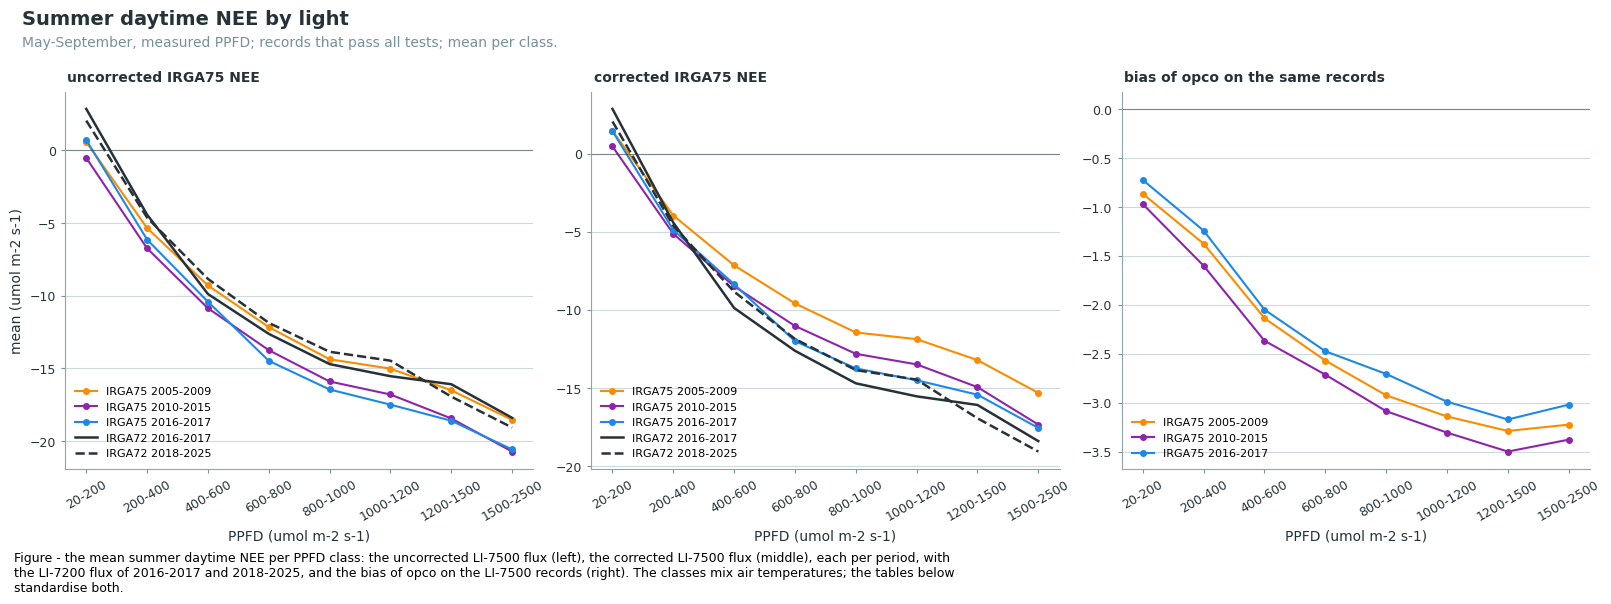

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(16, 6), sharex=True, layout='constrained')
_x = np.arange(len(PPFD_BINS) - 1)
_panels = [('IRGA75 uncorrected', 'uncorrected IRGA75 NEE'), ('IRGA75 corrected', 'corrected IRGA75 NEE'),
           ('opco bias', 'bias of opco on the same records')]
for _ax, (_s, _title) in zip(axs, _panels):
    for _p, _color in P75_COLORS.items():
        _g = LD[(LD['series'] == _s) & (LD['period'] == _p)].groupby('pbin', observed=False)['value']
        _m = _g.mean().where(_g.size() >= MIN_CELL_N)
        _ax.plot(_x, _m.to_numpy(), color=_color, marker='o', markersize=4, linewidth=1.5, label=f"IRGA75 {_p}")
    if _s != 'opco bias':
        for _p, _ls in P72_STYLE.items():
            _g = LD[(LD['series'] == 'IRGA72') & (LD['period'] == _p)].groupby('pbin', observed=False)['value']
            _ax.plot(_x, _g.mean().to_numpy(), color=cp.INK, linestyle=_ls, linewidth=1.8, label=f"IRGA72 {_p}")
    _ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
    _ax.set_xticks(_x, bin_labels(PPFD_BINS), fontsize=8, rotation=30)
    _ax.set_xlabel('PPFD (umol m-2 s-1)')
    cp.style_axes(_ax)
    cp.panel_label(_ax, _title)
    _ax.legend(frameon=False, fontsize=8, loc='lower left')
axs[0].set_ylabel('mean (umol m-2 s-1)')
cp.figure_title(fig, 'Summer daytime NEE by light',
                'May-September, measured PPFD; records that pass all tests; mean per class.')
figcap(fig, "the mean summer daytime NEE per PPFD class: the uncorrected LI-7500 flux (left), the corrected LI-7500 "
            "flux (middle), each per period, with the LI-7200 flux of 2016-2017 and 2018-2025, and the bias of opco on "
            "the LI-7500 records (right). The classes mix air temperatures; the tables below standardise both.")
plt.show()

### 📊 Plot: summer daytime NEE by air temperature class, high light only

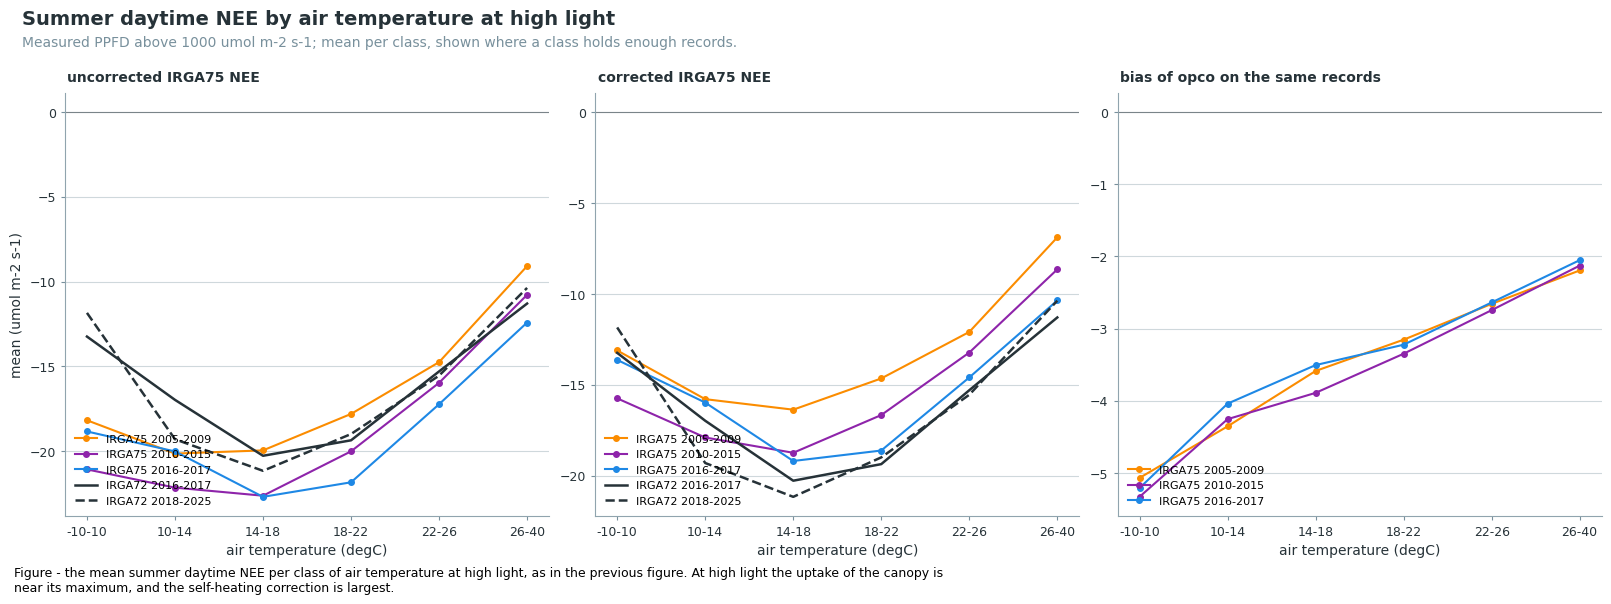

In [15]:
_hl = LD[LD['ppfd'] > 1000]
fig, axs = plt.subplots(1, 3, figsize=(16, 6), sharex=True, layout='constrained')
_x = np.arange(len(TA_BINS) - 1)
for _ax, (_s, _title) in zip(axs, _panels):
    for _p, _color in P75_COLORS.items():
        _g = _hl[(_hl['series'] == _s) & (_hl['period'] == _p)].groupby('tbin', observed=False)['value']
        _m = _g.mean().where(_g.size() >= MIN_CELL_N)
        _ax.plot(_x, _m.to_numpy(), color=_color, marker='o', markersize=4, linewidth=1.5, label=f"IRGA75 {_p}")
    if _s != 'opco bias':
        for _p, _ls in P72_STYLE.items():
            _g = _hl[(_hl['series'] == 'IRGA72') & (_hl['period'] == _p)].groupby('tbin', observed=False)['value']
            _m = _g.mean().where(_g.size() >= MIN_CELL_N)
            _ax.plot(_x, _m.to_numpy(), color=cp.INK, linestyle=_ls, linewidth=1.8, label=f"IRGA72 {_p}")
    _ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
    _ax.set_xticks(_x, bin_labels(TA_BINS), fontsize=8)
    _ax.set_xlabel('air temperature (degC)')
    cp.style_axes(_ax)
    cp.panel_label(_ax, _title)
    _ax.legend(frameon=False, fontsize=8, loc='lower left')
axs[0].set_ylabel('mean (umol m-2 s-1)')
cp.figure_title(fig, 'Summer daytime NEE by air temperature at high light',
                'Measured PPFD above 1000 umol m-2 s-1; mean per class, shown where a class holds enough records.')
figcap(fig, "the mean summer daytime NEE per class of air temperature at high light, as in the previous figure. "
            "At high light the uptake of the canopy is near its maximum, and the self-heating correction is largest.")
plt.show()

### 📋 Table: standardised summer daytime NEE per year

Each value is the mean over cells of PPFD and air temperature, weighted by the common summer
daytime distribution. `cover` is the share of that distribution the year's records cover.

In [16]:
_rows = []
for (_s, _y), _g in LD.groupby(['series', 'year']):
    _r = std_mean(_g, W_DAY, [_g['pbin'], _g['tbin']])
    _rows.append({'series': _s, 'year': _y, **_r.to_dict()})
STD_DAY = pd.DataFrame(_rows)
YEAR_DAY = STD_DAY.pivot(index='year', columns='series', values='mean')[SERIES_75 + ['opco bias', 'IRGA72']]
YEAR_DAY['cover IRGA75'] = STD_DAY[STD_DAY['series'] == 'IRGA75 corrected'].set_index('year')['cover']
YEAR_DAY['cover IRGA72'] = STD_DAY[STD_DAY['series'] == 'IRGA72'].set_index('year')['cover']
tabcap("per year, the standardised summer daytime mean (umol m-2 s-1) of the uncorrected and the corrected LI-7500 "
       "NEE, the bias of opco on the same records, and the LI-7200 NEE, with the covered share of the common "
       "distribution. The corrected NEE is the uncorrected NEE minus the bias")
display(YEAR_DAY.round(2))

Table - per year, the standardised summer daytime mean (umol m-2 s-1) of the uncorrected and the
corrected LI-7500 NEE, the bias of opco on the same records, and the LI-7200 NEE, with the covered
share of the common distribution. The corrected NEE is the uncorrected NEE minus the bias



series,IRGA75 uncorrected,IRGA75 corrected,opco bias,IRGA72,cover IRGA75,cover IRGA72
year,,,,,,
2005,-9.36,-7.10,-2.26,NaN,0.99,NaN
2006,-8.63,-6.51,-2.12,NaN,0.98,NaN
2007,-10.29,-8.33,-1.95,NaN,0.95,NaN
2008,-10.58,-8.21,-2.37,NaN,0.98,NaN
2009,-10.40,-8.03,-2.37,NaN,0.97,NaN
2010,-11.51,-9.07,-2.43,NaN,0.97,NaN
2011,-11.45,-9.22,-2.23,NaN,0.95,NaN
2012,-11.56,-9.29,-2.26,NaN,0.98,NaN
2013,-11.84,-9.38,-2.46,NaN,0.99,NaN


### 📊 Plot: standardised summer daytime NEE per year

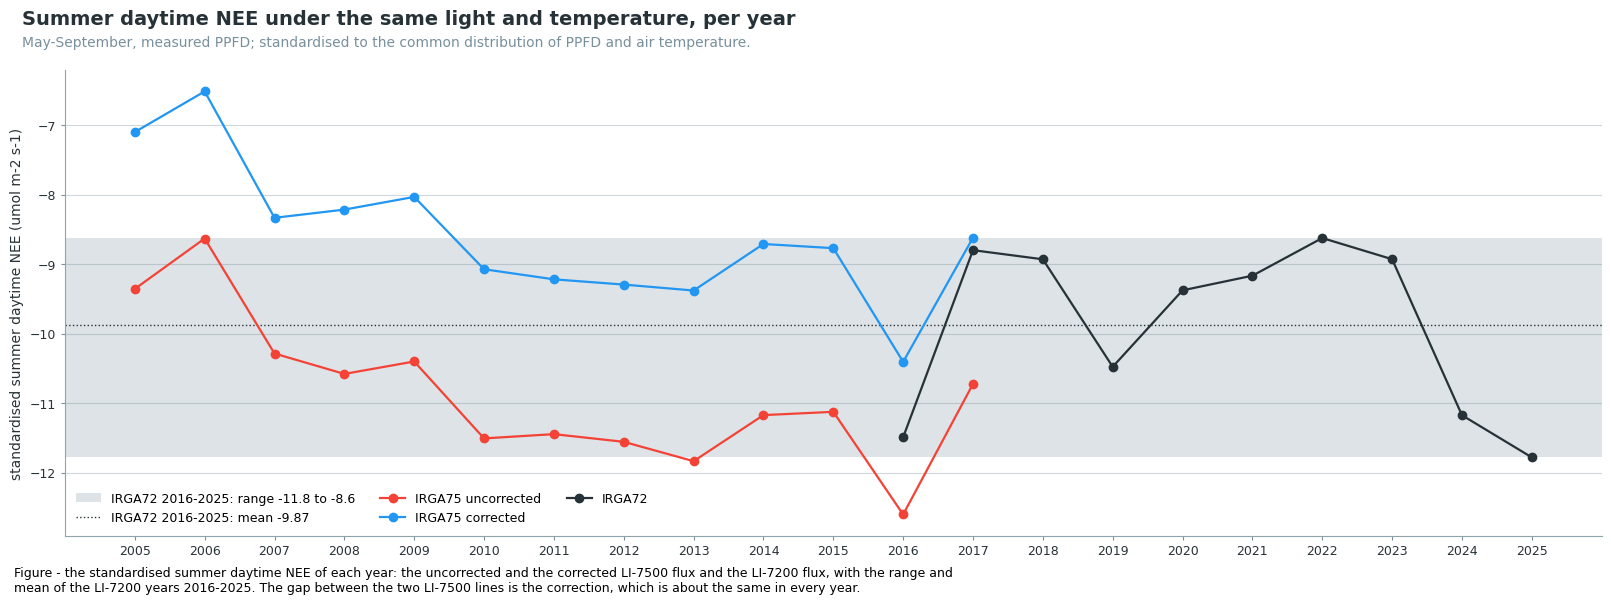

In [17]:
fig, ax = plt.subplots(figsize=(16, 6), layout='constrained')
_y72 = YEAR_DAY['IRGA72'].dropna()
_ref = _y72.loc[2016:2025]
ax.axhspan(_ref.min(), _ref.max(), color=cp.MUTED, alpha=0.25, linewidth=0,
           label=f"IRGA72 2016-2025: range {_ref.min():.1f} to {_ref.max():.1f}")
ax.axhline(_ref.mean(), color=cp.INK, linewidth=1, linestyle=':', label=f"IRGA72 2016-2025: mean {_ref.mean():.2f}")
for _s in SERIES_75 + ['IRGA72']:
    _v = YEAR_DAY[_s].dropna()
    ax.plot(_v.index, _v.to_numpy(), color=SERIES_COLORS[_s], marker='o', linewidth=1.6, label=_s)
ax.set_xticks(YEAR_DAY.index)
ax.set_ylabel('standardised summer daytime NEE (umol m-2 s-1)')
cp.style_axes(ax)
ax.legend(frameon=False, fontsize=9, loc='lower left', ncol=3)
cp.figure_title(fig, 'Summer daytime NEE under the same light and temperature, per year',
                'May-September, measured PPFD; standardised to the common distribution of PPFD and air temperature.')
figcap(fig, "the standardised summer daytime NEE of each year: the uncorrected and the corrected LI-7500 flux and the "
            "LI-7200 flux, with the range and mean of the LI-7200 years 2016-2025. The gap between the two LI-7500 "
            "lines is the correction, which is about the same in every year.")
plt.show()

### 📋 Table: standardised summer daytime NEE per period and the gaps between them

`selection offset`: in 2016-2017 both analysers measured, but each keeps its own records after the
tests. The corrected LI-7500 minus the LI-7200 over these own records is the offset that a
comparison of the early LI-7500 years with the LI-7200 years carries by construction. On the
common records of the overlap the offset is near zero (see the overlap table below).

In [18]:
def period_mean(series, years):
    v = YEAR_DAY[series].loc[years[0]:years[1]].dropna()
    return v.mean(), v.std(), len(v)


_rows = {}
for _s in SERIES_75 + ['opco bias']:
    for _p, _yy in PERIODS_75.items():
        _rows[(_s, _p)] = period_mean(_s, _yy)
for _p, _yy in {'2016-2017': (2016, 2017), '2018-2025': (2018, 2025), '2016-2025': (2016, 2025)}.items():
    _rows[('IRGA72', _p)] = period_mean('IRGA72', _yy)
PER_DAY = pd.DataFrame(_rows, index=['mean of years', 'sd of years', 'years']).T
tabcap("the standardised summer daytime NEE per period (umol m-2 s-1): the mean of the yearly values, their standard "
       "deviation and the number of years")
display(PER_DAY.round(2))

REF72 = PER_DAY.loc[('IRGA72', '2016-2025'), 'mean of years']
OFFSET = PER_DAY.loc[('IRGA75 corrected', '2016-2017'), 'mean of years'] - PER_DAY.loc[('IRGA72', '2016-2017'), 'mean of years']
TARGET = REF72 + OFFSET   # what the corrected early LI-7500 would show if the ecosystem were that of 2016-2025
print(f"IRGA72 2016-2025: {REF72:.2f}; selection offset (IRGA75 corrected - IRGA72, 2016-2017): {OFFSET:+.2f}; "
      f"target for the corrected IRGA75: {TARGET:.2f} umol m-2 s-1")
for _p in PERIODS_75:
    _c = PER_DAY.loc[('IRGA75 corrected', _p), 'mean of years']
    _u = PER_DAY.loc[('IRGA75 uncorrected', _p), 'mean of years']
    print(f"{_p}: corrected {_c:.2f} (gap to target {_c - TARGET:+.2f}), uncorrected {_u:.2f} "
          f"(gap to target {_u - TARGET:+.2f})")

Table - the standardised summer daytime NEE per period (umol m-2 s-1): the mean of the yearly
values, their standard deviation and the number of years



mean of years  sd of years  years
IRGA75 uncorrected 2005-2009          -9.85         0.83    5.0
                   2010-2015         -11.44         0.26    6.0
                   2016-2017         -11.66         1.33    2.0
IRGA75 corrected   2005-2009          -7.64         0.79    5.0
                   2010-2015          -9.07         0.28    6.0
                   2016-2017          -9.51         1.26    2.0
opco bias          2005-2009          -2.21         0.18    5.0
                   2010-2015          -2.37         0.10    6.0
                   2016-2017          -2.15         0.06    2.0
IRGA72             2016-2017         -10.14         1.90    2.0
                   2018-2025          -9.81         1.18    8.0
                   2016-2025          -9.87         1.23   10.0

IRGA72 2016-2025: -9.87; selection offset (IRGA75 corrected - IRGA72, 2016-2017): +0.63; target for the corrected IRGA75: -9.24 umol m-2 s-1
2005-2009: corrected -7.64 (gap to target +1.60), uncorrected -9.85 (gap to target -0.61)
2010-2015: corrected -9.07 (gap to target +0.17), uncorrected -11.44 (gap to target -2.20)
2016-2017: corrected -9.51 (gap to target -0.27), uncorrected -11.66 (gap to target -2.42)


### 📋 Table: residual against a model of the LI-7200 years, summer daytime

A second way to match conditions, which adds VPD and the day of year (phenology) to light and
temperature: a gradient-boosted model of the LI-7200 `NEE` of 2016-2025 on PPFD, air temperature,
VPD and day of year, and the mean residual of each series and year against it. A positive residual
means less uptake than the LI-7200 years under the same conditions. The LI-7200 residuals are in
sample. The VPD probe changed in 2016; by day in summer the two probes differ little.

In [19]:
_f = ['ppfd', 'ta', 'vpd', 'doy']
_r72 = LD[(LD['series'] == 'IRGA72') & (LD['year'] <= 2025)].dropna(subset=_f + ['value'])
REFMODEL = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, min_samples_leaf=40,
                                         random_state=0).fit(_r72[_f], _r72['value'])
_ld = LD[LD['series'] != 'opco bias'].dropna(subset=_f + ['value']).copy()
_ld['residual'] = _ld['value'] - REFMODEL.predict(_ld[_f])
RESID_DAY = _ld.groupby(['year', 'series'])['residual'].mean().unstack()[SERIES_75 + ['IRGA72']]
tabcap("per year, the mean residual (umol m-2 s-1) of the uncorrected and the corrected LI-7500 NEE and of the LI-7200 "
       "NEE against a model of the LI-7200 NEE of 2016-2025 on PPFD, air temperature, VPD and day of year, "
       "summer daytime records that pass all tests")
display(RESID_DAY.round(2))

Table - per year, the mean residual (umol m-2 s-1) of the uncorrected and the corrected LI-7500 NEE
and of the LI-7200 NEE against a model of the LI-7200 NEE of 2016-2025 on PPFD, air temperature, VPD
and day of year, summer daytime records that pass all tests



series,IRGA75 uncorrected,IRGA75 corrected,IRGA72
year,,,
2005,1.03,3.72,NaN
2006,1.31,3.75,NaN
2007,0.06,2.46,NaN
2008,-0.63,2.20,NaN
2009,-0.49,2.28,NaN
2010,-1.43,1.41,NaN
2011,-2.19,0.51,NaN
2012,-1.50,1.22,NaN
2013,-2.49,0.39,NaN


### 📊 Plot: summer nighttime NEE by air temperature class

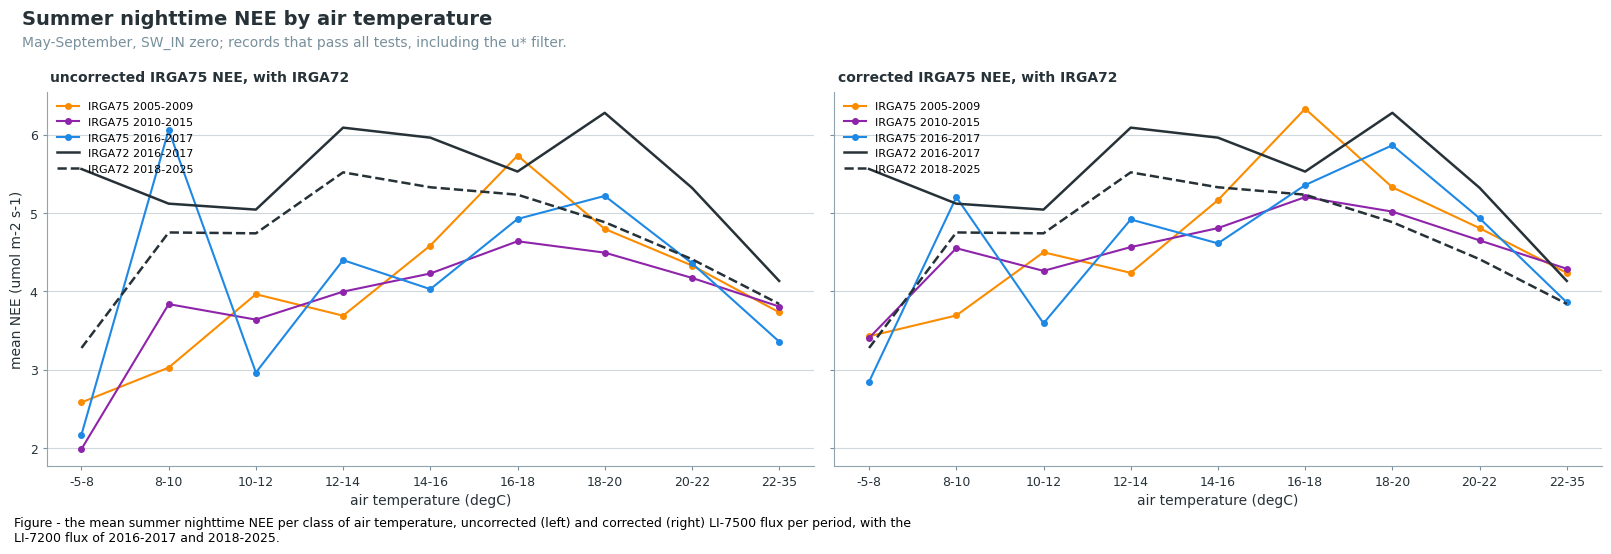

In [20]:
LN = L[L['summer'] & (L['sw'] <= 0) & (L['year'] >= FIRST_LIGHT_YEAR)].copy()
LN['tbin'] = pd.cut(LN['ta'], NIGHT_TA_BINS)
fig, axs = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True, layout='constrained')
_x = np.arange(len(NIGHT_TA_BINS) - 1)
for _ax, _s in zip(axs, SERIES_75):
    for _p, _color in P75_COLORS.items():
        _g = LN[(LN['series'] == _s) & (LN['period'] == _p)].groupby('tbin', observed=False)['value']
        _ax.plot(_x, _g.mean().where(_g.size() >= MIN_CELL_N).to_numpy(), color=_color, marker='o', markersize=4,
                 linewidth=1.5, label=f"IRGA75 {_p}")
    for _p, _ls in P72_STYLE.items():
        _g = LN[(LN['series'] == 'IRGA72') & (LN['period'] == _p)].groupby('tbin', observed=False)['value']
        _ax.plot(_x, _g.mean().where(_g.size() >= MIN_CELL_N).to_numpy(), color=cp.INK, linestyle=_ls,
                 linewidth=1.8, label=f"IRGA72 {_p}")
    _ax.set_xticks(_x, bin_labels(NIGHT_TA_BINS), fontsize=8)
    _ax.set_xlabel('air temperature (degC)')
    cp.style_axes(_ax)
    cp.panel_label(_ax, f"{_s.replace('IRGA75 ', '')} IRGA75 NEE, with IRGA72")
    _ax.legend(frameon=False, fontsize=8, loc='upper left')
axs[0].set_ylabel('mean NEE (umol m-2 s-1)')
cp.figure_title(fig, 'Summer nighttime NEE by air temperature',
                'May-September, SW_IN zero; records that pass all tests, including the u* filter.')
figcap(fig, "the mean summer nighttime NEE per class of air temperature, uncorrected (left) and corrected (right) "
            "LI-7500 flux per period, with the LI-7200 flux of 2016-2017 and 2018-2025.")
plt.show()

### 📋 Table: standardised summer nighttime NEE per year

In [21]:
_rows = []
for (_s, _y), _g in LN.groupby(['series', 'year']):
    _rows.append({'series': _s, 'year': _y, **std_mean(_g, W_NIGHT, [_g['tbin']]).to_dict()})
STD_NIGHT = pd.DataFrame(_rows)
YEAR_NIGHT = STD_NIGHT.pivot(index='year', columns='series', values='mean')[SERIES_75 + ['opco bias', 'IRGA72']]
YEAR_NIGHT['n IRGA75'] = STD_NIGHT[STD_NIGHT['series'] == 'IRGA75 corrected'].set_index('year')['n']
YEAR_NIGHT['n IRGA72'] = STD_NIGHT[STD_NIGHT['series'] == 'IRGA72'].set_index('year')['n']
tabcap("per year, the summer nighttime mean (umol m-2 s-1) of each series, standardised to the common distribution of "
       "nighttime air temperature, and the number of records")
display(YEAR_NIGHT.round(2))
_e = YEAR_NIGHT.loc[EARLY[0]:EARLY[1], 'IRGA75 corrected'].mean()
_r = YEAR_NIGHT.loc[2016:2025, 'IRGA72']
print(f"summer nights: corrected IRGA75 2005-2009 {_e:.2f}; IRGA72 2016-2025 {_r.mean():.2f} "
      f"(range {_r.min():.2f} to {_r.max():.2f}) umol m-2 s-1")

Table - per year, the summer nighttime mean (umol m-2 s-1) of each series, standardised to the
common distribution of nighttime air temperature, and the number of records



series,IRGA75 uncorrected,IRGA75 corrected,opco bias,IRGA72,n IRGA75,n IRGA72
year,,,,,,
2005,3.95,4.53,-0.58,NaN,863.0,NaN
2006,4.56,5.13,-0.57,NaN,911.0,NaN
2007,4.42,4.91,-0.49,NaN,762.0,NaN
2008,4.46,5.05,-0.59,NaN,962.0,NaN
2009,3.95,4.57,-0.61,NaN,866.0,NaN
2010,4.49,5.16,-0.67,NaN,730.0,NaN
2011,3.52,4.11,-0.59,NaN,728.0,NaN
2012,4.18,4.74,-0.57,NaN,707.0,NaN
2013,4.63,5.19,-0.56,NaN,853.0,NaN


summer nights: corrected IRGA75 2005-2009 4.84; IRGA72 2016-2025 4.97 (range 4.09 to 5.54) umol m-2 s-1


### 📋 Table: both analysers on their common records in the summers of the overlap

Records of 2016-2017 where both analysers pass all tests. This is where the size of the summer
correction is checked against the LI-7200 directly.

In [22]:
_c = A.loc['2016':'2017']
_common = Q75.loc['2016':'2017'] & Q72.reindex(_c.index, fill_value=False) & _c['summer']
_o = pd.DataFrame({'IRGA72': B[NEE_COL].reindex(_c.index)[_common], 'IRGA75 uncorrected': _c.loc[_common, 'UNC'],
                   'IRGA75 corrected': _c.loc[_common, NEE_COL]})
_o['day'] = _c.loc[_common, 'sw'] > DAY_SW
_rows = {}
for _name, _sel in (('daytime', _o['day']), ('nighttime', ~_o['day']), ('all', _o['day'] | ~_o['day'])):
    _s = _o[_sel]
    _r = {'records': len(_s)}
    for _k in ('IRGA72', 'IRGA75 uncorrected', 'IRGA75 corrected'):
        _r[f'{_k} sum gC'] = _s[_k].sum() * GC_PER_HALFHOUR
    _r['uncorrected / IRGA72'] = _s['IRGA75 uncorrected'].sum() / _s['IRGA72'].sum()
    _r['corrected / IRGA72'] = _s['IRGA75 corrected'].sum() / _s['IRGA72'].sum()
    _rows[_name] = _r
OVERLAP = pd.DataFrame(_rows).T
tabcap("summers (May-September) 2016-2017, records where both analysers pass all tests: the sums of the LI-7200 NEE "
       "and of the uncorrected and the corrected LI-7500 NEE (gC m-2), and their ratios to the LI-7200 sum, by day "
       "(SW_IN above 12 W m-2) and by night. The correction is in sample here")
display(OVERLAP.round(3))

Table - summers (May-September) 2016-2017, records where both analysers pass all tests: the sums of
the LI-7200 NEE and of the uncorrected and the corrected LI-7500 NEE (gC m-2), and their ratios to
the LI-7200 sum, by day (SW_IN above 12 W m-2) and by night. The correction is in sample here



,records,IRGA72 sum gC,IRGA75 uncorrected sum gC,IRGA75 corrected sum gC,uncorrected / IRGA72,corrected / IRGA72
daytime,4190.0,-1199.598,-1428.188,-1202.599,1.191,1.003
nighttime,1433.0,158.513,135.554,149.405,0.855,0.943
all,5623.0,-1041.084,-1292.635,-1053.193,1.242,1.012


## 🧪 4 Tests of the self-heating from the LI-7500 alone

### Transfer between the two training years

opco is refitted on 2016 alone and on 2017 alone, and each model predicts the other year. If the
summer daytime correction transfers between years without loss, the corrected flux of the left-out
year matches the LI-7200 there. Each model also predicts the early years: if the back-transfer
depended strongly on the training year, the two predictions would differ.

The training half-hours are those where `NEE_L3.1_L3.2_QCF` of both analysers is valid (Levels 2
to 3.2, no u* filter) and the LI-7200 flow rate is at least 8 l min-1. This approximates the
selection of `01`, which reruns Levels 2 to 3.2. A model fitted on both years with this selection
is shown next to the stored correction as a check of the approximation.

In [23]:
DRV_OPCO = pd.DataFrame({'fc': A['FC'], 'heat': A['HEAT_OPCO'], 'wpl_h': A['WPL_H_OPCO'], 'ta': A[TA_OPCO],
                         'sw_in': A[SW_OPCO], 'ustar': A['USTAR'], 'u': A['WS'],
                         'isday': (A[SW_OPCO] > DAY_SW).astype(float), 'k_op': A['K_OP_OPCO']})
_tr = DRV_OPCO.loc[f'{TRAIN[0]}':f'{TRAIN[1]}'].copy()
_tr['dfc'] = _tr['fc'] - B['FC'].reindex(_tr.index)
_keep = (A[NEE_L32_COL].reindex(_tr.index).notna() & B[NEE_L32_COL].reindex(_tr.index).notna()
         & (B[FLOW_COL].reindex(_tr.index) >= FLOW_MIN) & _tr[['dfc', 'heat', 'wpl_h']].notna().all(axis=1))
_t0 = datetime.now()
MODELS = {}
for _name, _sel in (('both years', _keep), ('2016 only', _keep & (_tr.index.year == 2016)),
                    ('2017 only', _keep & (_tr.index.year == 2017))):
    MODELS[_name] = PhysBiasModel(features_xi=FEATURES_XI, features_k=FEATURES_K,
                                  setup=f"transfer check, {_name}").fit(_tr[_sel])
    print(f"{_name:<10} {MODELS[_name].trained['n']:>6,} training half-hours")
PRED = pd.DataFrame({_n: _m.predict(DRV_OPCO)['bias'] for _n, _m in MODELS.items()})
PRED['stored (01)'] = A['BIAS_OPCO']
print(f"fitted in {(datetime.now() - _t0).seconds} s")

both years 15,019 training half-hours


2016 only   6,433 training half-hours


2017 only   8,586 training half-hours


fitted in 11 s


#### 📋 Table: corrected flux of each training year, predicted by the model of the other year

In [24]:
_sdm = A['summer'] & (A[SW_OPCO] > DAY_SW) & Q75 & Q72.reindex(A.index, fill_value=False)
_rows = []
for _year, _model in ((2016, '2017 only'), (2017, '2016 only'), (2016, '2016 only'), (2017, '2017 only'),
                      (2016, 'stored (01)'), (2017, 'stored (01)')):
    _s = _sdm & (A['year'] == _year)
    _ref = B[NEE_COL].reindex(A.index)[_s]
    _cor = A.loc[_s, 'UNC'] - PRED.loc[_s, _model]
    _rows.append({'year': _year, 'model': _model,
                  'sample': 'out of sample' if _model == f"{2017 if _year == 2016 else 2016} only" else 'in sample',
                  'records': int(_s.sum()), 'IRGA72': _ref.mean(), 'IRGA75 uncorrected': A.loc[_s, 'UNC'].mean(),
                  'IRGA75 corrected': _cor.mean(), 'corrected - IRGA72': _cor.mean() - _ref.mean(),
                  'corrected / IRGA72 (sum)': _cor.sum() / _ref.sum()})
TRANSFER = pd.DataFrame(_rows).set_index(['year', 'model'])
tabcap("summer daytime records of 2016 and 2017 where both analysers pass all tests: the mean LI-7200 NEE, the mean "
       "uncorrected LI-7500 NEE and the mean LI-7500 NEE corrected with each model (umol m-2 s-1), and the ratio of "
       "the corrected to the LI-7200 sum. The rows with the model of the other year are out of sample")
display(TRANSFER.round(3))

Table - summer daytime records of 2016 and 2017 where both analysers pass all tests: the mean
LI-7200 NEE, the mean uncorrected LI-7500 NEE and the mean LI-7500 NEE corrected with each model
(umol m-2 s-1), and the ratio of the corrected to the LI-7200 sum. The rows with the model of the
other year are out of sample



,,sample,records,IRGA72,IRGA75 uncorrected,IRGA75 corrected,corrected - IRGA72,corrected / IRGA72 (sum)
year,model,,,,,,,
2016,2017 only,out of sample,1894,-14.585,-17.161,-14.531,0.053,0.996
2017,2016 only,out of sample,2296,-12.135,-14.615,-12.091,0.045,0.996
2016,2016 only,in sample,1894,-14.585,-17.161,-14.584,0.000,1.000
2017,2017 only,in sample,2296,-12.135,-14.615,-12.086,0.050,0.996
2016,stored (01),in sample,1894,-14.585,-17.161,-14.647,-0.063,1.004
2017,stored (01),in sample,2296,-12.135,-14.615,-12.144,-0.009,1.001


#### 📋 Table: summer daytime bias of the early years, predicted by each model

In [25]:
_m = A['summer'] & (A[SW_OPCO] > DAY_SW) & Q75
BACK = PRED[_m].groupby(A.loc[_m, 'year']).mean()
tabcap("per year, the mean bias (umol m-2 s-1) over the summer daytime records that pass all tests, predicted by the "
       "models fitted on both years, on 2016 only and on 2017 only, and the bias stored by 01")
display(BACK.round(2))
_e = BACK.loc[EARLY[0]:EARLY[1]].mean()
print("2005-2009 mean: " + ", ".join(f"{k} {v:.2f}" for k, v in _e.items()))

Table - per year, the mean bias (umol m-2 s-1) over the summer daytime records that pass all tests,
predicted by the models fitted on both years, on 2016 only and on 2017 only, and the bias stored by
01



,both years,2016 only,2017 only,stored (01)
year,,,,
2004,-2.57,-2.65,-2.52,-2.49
2005,-2.77,-2.88,-2.90,-2.69
2006,-2.53,-2.51,-2.57,-2.45
2007,-2.43,-2.49,-2.57,-2.40
2008,-2.95,-3.11,-2.98,-2.84
2009,-2.83,-2.95,-2.87,-2.75
2010,-2.92,-3.15,-2.95,-2.86
2011,-2.88,-2.88,-2.97,-2.72
2012,-2.76,-2.88,-2.85,-2.72


2005-2009 mean: both years -2.70, 2016 only -2.79, 2017 only -2.78, stored (01) -2.63


### Summer: the dependence of the bias on wind speed

The heat that the warm sensor head gives to the air in its path depends on how well it is
ventilated: at low wind the head is warmer relative to the air and the error is larger. At the
same light and air temperature, the bias is therefore more negative at low wind than at high wind.
This gradient is a signature of the self-heating in the LI-7500 flux itself, and it can be
measured in every year without the LI-7200.

Per year, the summer daytime records with measured PPFD above 200 umol m-2 s-1 are grouped into
cells of PPFD and air temperature, and each value is taken as its deviation from the mean of its
cell. The *wind contrast* is the mean deviation at high wind speed (2.5 to 5 m s-1) minus that at
low wind speed (up to 1.5 m s-1). For the uncorrected flux it is the sum of the contrast of the
ecosystem and that of the bias. With a scaling factor `s` of the true bias:
`contrast_uncorrected = contrast_ecosystem + s · contrast_bias`.

The ecosystem contrast is taken from the corrected LI-7500 flux of 2010-2017, where `s = 1` is
assumed (and checked against the LI-7200 in 2016-2017, first table). Its uncertainty is the
year-to-year standard deviation of the contrast of the LI-7200 years 2016-2025.

In [26]:
def wind_contrast(d, cols):
    """Per year: high-wind minus low-wind mean of each column, each value as its deviation from its cell mean."""
    s = d.copy()
    s['cell'] = pd.cut(s['ppfd'], WIND_PPFD_BINS, labels=False) * 100 + pd.cut(s['ta'], TA_BINS, labels=False)
    s['wclass'] = np.select([s['WS'] <= WIND_LOW, (s['WS'] > WIND_HIGH[0]) & (s['WS'] <= WIND_HIGH[1])],
                            ['low', 'high'], 'mid')
    rows = {}
    for _y, _g in s.groupby('year'):
        _r = {'n low': int((_g['wclass'] == 'low').sum()), 'n high': int((_g['wclass'] == 'high').sum())}
        for _c in cols:
            _dev = _g[_c] - _g.groupby('cell')[_c].transform('mean')
            _m = _dev.groupby(_g['wclass']).mean()
            _r[_c] = _m.get('high', np.nan) - _m.get('low', np.nan)
        rows[_y] = _r
    return pd.DataFrame(rows).T


_sel = lambda d: d['summer'] & d['ppfd_meas'] & (d['ppfd'] > WIND_PPFD_BINS[0])
_a = A[_sel(A) & Q75 & (A['year'] >= FIRST_LIGHT_YEAR)]
WIND75 = wind_contrast(_a, ['UNC', 'BIAS_OPCO', NEE_COL]).rename(
    columns={'UNC': 'uncorrected', 'BIAS_OPCO': 'bias', NEE_COL: 'corrected'})
WIND72 = wind_contrast(B[_sel(B) & Q72], [NEE_COL]).rename(columns={NEE_COL: 'IRGA72'})
# The overlap on its common records: the true bias (uncorrected minus IRGA72) against the bias of opco.
_o = A[_sel(A) & Q75 & Q72.reindex(A.index, fill_value=False)].copy()
_o['IRGA72'] = B[NEE_COL].reindex(_o.index)
_o['true bias'] = _o['UNC'] - _o['IRGA72']
WIND_OV = wind_contrast(_o, ['true bias', 'BIAS_OPCO', 'IRGA72', NEE_COL]).rename(
    columns={'BIAS_OPCO': 'bias of opco', NEE_COL: 'IRGA75 corrected'})
WIND_REF = WIND75.loc[WIND_REF_YEARS[0]:WIND_REF_YEARS[1], 'corrected'].mean()
SD_ECO = WIND72.loc[2016:2025, 'IRGA72'].std()
WIND75['s'] = (WIND75['uncorrected'] - WIND_REF) / WIND75['bias']
print(f"ecosystem wind contrast (corrected IRGA75 {WIND_REF_YEARS[0]}-{WIND_REF_YEARS[1]}): {WIND_REF:+.2f}; "
      f"year-to-year sd of the IRGA72 contrast 2016-2025: {SD_ECO:.2f} umol m-2 s-1")

ecosystem wind contrast (corrected IRGA75 2010-2017): +0.06; year-to-year sd of the IRGA72 contrast 2016-2025: 1.00 umol m-2 s-1


#### 📋 Table: wind contrast on the common records of the overlap

In [27]:
tabcap("summers 2016 and 2017, daytime records with PPFD above 200 umol m-2 s-1 where both analysers pass all tests: "
       "the wind contrast (high minus low wind speed, umol m-2 s-1) of the true bias (uncorrected LI-7500 minus "
       "LI-7200), of the bias of opco, of the LI-7200 NEE and of the corrected LI-7500 NEE, and the record numbers "
       "in the two wind classes. opco is in sample here")
display(WIND_OV.round(2))

Table - summers 2016 and 2017, daytime records with PPFD above 200 umol m-2 s-1 where both analysers
pass all tests: the wind contrast (high minus low wind speed, umol m-2 s-1) of the true bias
(uncorrected LI-7500 minus LI-7200), of the bias of opco, of the LI-7200 NEE and of the corrected
LI-7500 NEE, and the record numbers in the two wind classes. opco is in sample here



,n low,n high,true bias,bias of opco,IRGA72,IRGA75 corrected
2016,422.0,512.0,1.77,1.72,-0.18,-0.12
2017,406.0,803.0,2.12,1.88,-0.58,-0.33


#### 📊 Plot: wind contrast of the summer daytime flux, per year

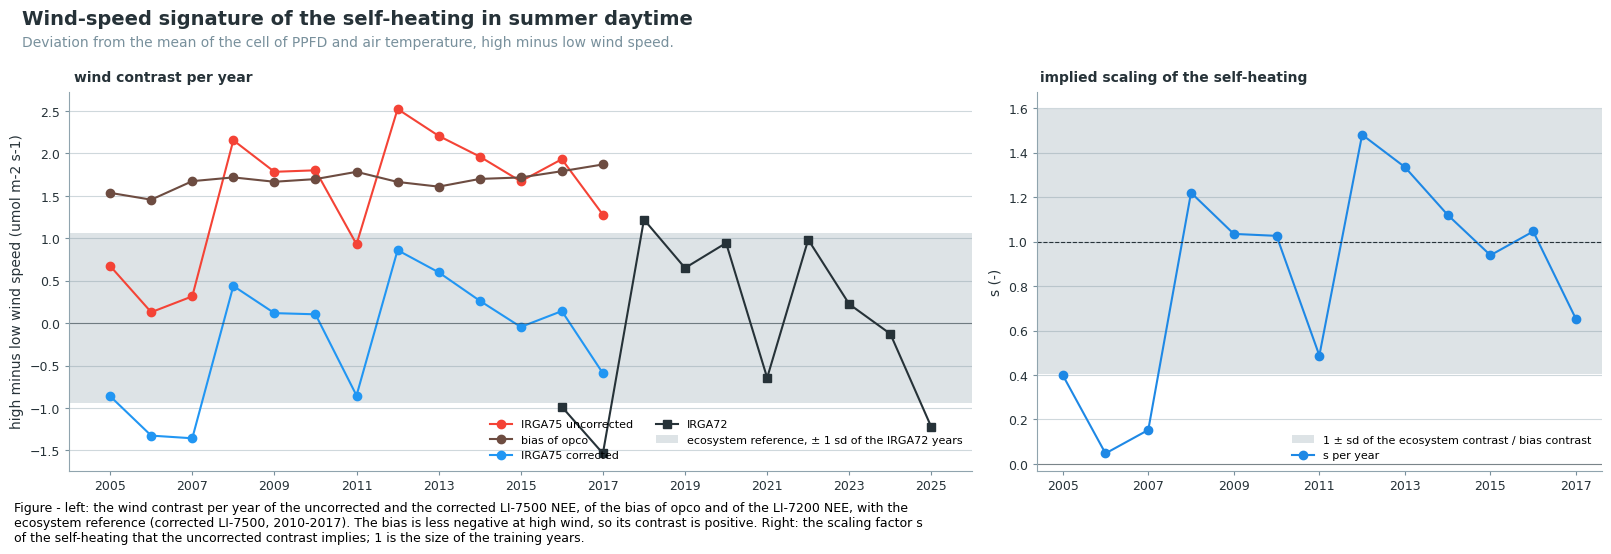

In [28]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5.5), layout='constrained', width_ratios=[1.6, 1])
_ax = axs[0]
for _c, _color, _label in (('uncorrected', SERIES_COLORS['IRGA75 uncorrected'], 'IRGA75 uncorrected'),
                           ('bias', SERIES_COLORS['opco bias'], 'bias of opco'),
                           ('corrected', SERIES_COLORS['IRGA75 corrected'], 'IRGA75 corrected')):
    _ax.plot(WIND75.index, WIND75[_c], color=_color, marker='o', linewidth=1.5, label=_label)
_ax.plot(WIND72.index, WIND72['IRGA72'], color=cp.INK, marker='s', linewidth=1.5, label='IRGA72')
_ax.axhspan(WIND_REF - SD_ECO, WIND_REF + SD_ECO, color=cp.MUTED, alpha=0.25, linewidth=0,
            label='ecosystem reference, ± 1 sd of the IRGA72 years')
_ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
_ax.set_xticks(range(FIRST_LIGHT_YEAR, 2026, 2))
_ax.set_ylabel('high minus low wind speed (umol m-2 s-1)')
cp.style_axes(_ax)
cp.panel_label(_ax, 'wind contrast per year')
_ax.legend(frameon=False, fontsize=8, loc='lower right', ncol=2)
_ax = axs[1]
_band = SD_ECO / WIND75['bias'].mean()
_ax.axhspan(1 - _band, 1 + _band, color=cp.MUTED, alpha=0.25, linewidth=0,
            label='1 ± sd of the ecosystem contrast / bias contrast')
_ax.plot(WIND75.index, WIND75['s'], color=cp.TEST_COLORS[3], marker='o', linewidth=1.5, label='s per year')
_ax.axhline(1, color=cp.INK, linewidth=0.8, linestyle='--')
_ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
_ax.set_xticks(range(FIRST_LIGHT_YEAR, 2018, 2))
_ax.set_ylabel('s (-)')
cp.style_axes(_ax)
cp.panel_label(_ax, 'implied scaling of the self-heating')
_ax.legend(frameon=False, fontsize=8, loc='lower right')
cp.figure_title(fig, 'Wind-speed signature of the self-heating in summer daytime',
                'Deviation from the mean of the cell of PPFD and air temperature, high minus low wind speed.')
figcap(fig, "left: the wind contrast per year of the uncorrected and the corrected LI-7500 NEE, of the bias of opco and of "
            "the LI-7200 NEE, with the ecosystem reference (corrected LI-7500, 2010-2017). The bias is less negative at "
            "high wind, so its contrast is positive. Right: the scaling factor s of the self-heating that the "
            "uncorrected contrast implies; 1 is the size of the training years.")
plt.show()

#### 📋 Table: wind contrast per year and the scaling factor it implies

In [29]:
tabcap("per year, summer daytime: the record numbers at low and high wind speed and the wind contrast (umol m-2 s-1) of "
       "the uncorrected LI-7500 NEE, the bias of opco and the corrected LI-7500 NEE, with the implied scaling factor s "
       "of the self-heating, and the contrast of the LI-7200 NEE")
display(WIND75.join(WIND72[['IRGA72']], how='outer').round(2))

Table - per year, summer daytime: the record numbers at low and high wind speed and the wind
contrast (umol m-2 s-1) of the uncorrected LI-7500 NEE, the bias of opco and the corrected LI-7500
NEE, with the implied scaling factor s of the self-heating, and the contrast of the LI-7200 NEE



,n low,n high,uncorrected,bias,corrected,s,IRGA72
2005,589.0,545.0,0.67,1.53,-0.86,0.40,NaN
2006,638.0,491.0,0.13,1.45,-1.33,0.05,NaN
2007,555.0,560.0,0.32,1.67,-1.36,0.15,NaN
2008,618.0,649.0,2.15,1.72,0.44,1.22,NaN
2009,666.0,526.0,1.78,1.67,0.12,1.03,NaN
2010,560.0,404.0,1.80,1.70,0.10,1.03,NaN
2011,527.0,565.0,0.93,1.78,-0.85,0.49,NaN
2012,495.0,573.0,2.52,1.66,0.86,1.48,NaN
2013,535.0,510.0,2.21,1.61,0.60,1.34,NaN
2014,659.0,516.0,1.96,1.70,0.26,1.12,NaN


#### 📋 Table: scaling factor of the self-heating per group of years, from the wind contrast

In [30]:
_nref = WIND_REF_YEARS[1] - WIND_REF_YEARS[0] + 1
_rows = {}
for _grp, (_y0, _y1) in WIND_GROUPS.items():
    _w = WIND75.loc[_y0:_y1]
    _cb = _w['bias'].mean()
    _sv = (_w['uncorrected'].mean() - WIND_REF) / _cb
    _se = SD_ECO * np.sqrt(1 / len(_w) + 1 / _nref) / abs(_cb)
    _rows[_grp] = {'years': len(_w), 'uncorrected contrast': _w['uncorrected'].mean(), 'bias contrast': _cb,
                   'corrected contrast': _w['corrected'].mean(), 's': _sv, 's SE': _se,
                   's 95 % low': _sv - 1.96 * _se, 's 95 % high': _sv + 1.96 * _se}
S_WIND = pd.DataFrame(_rows).T
tabcap(f"per group of years, the mean wind contrasts (umol m-2 s-1) and the scaling factor s of the self-heating, "
       f"with a standard error from the year-to-year sd of the ecosystem contrast of the LI-7200 years "
       f"({SD_ECO:.2f}) and its 95 % range. The reference years {WIND_REF_YEARS[0]}-{WIND_REF_YEARS[1]} "
       "have s near 1 by construction")
display(S_WIND.round(2))
# The same test with the smaller year-to-year spread of the corrected LI-7500 contrast in the reference years.
_sd75 = WIND75.loc[WIND_REF_YEARS[0]:WIND_REF_YEARS[1], 'corrected'].std()
for _grp in ('2005-2007', '2008-2009'):
    _r = S_WIND.loc[_grp]
    _se_lo = _sd75 * np.sqrt(1 / _r['years'] + 1 / _nref) / abs(_r['bias contrast'])
    print(f"{_grp}: s = {_r['s']:.2f}; distance from s = 1 in standard errors: {(1 - _r['s']) / _r['s SE']:.1f} "
          f"(spread of the IRGA72 years, sd {SD_ECO:.2f}), {(1 - _r['s']) / _se_lo:.1f} "
          f"(spread of the IRGA75 reference years, sd {_sd75:.2f})")

Table - per group of years, the mean wind contrasts (umol m-2 s-1) and the scaling factor s of the
self-heating, with a standard error from the year-to-year sd of the ecosystem contrast of the
LI-7200 years (1.00) and its 95 % range. The reference years 2010-2017 have s near 1 by construction



,years,uncorrected contrast,bias contrast,corrected contrast,s,s SE,s 95 % low,s 95 % high
2005-2007,3.0,0.37,1.55,-1.18,0.20,0.44,-0.66,1.06
2008-2009,2.0,1.97,1.69,0.28,1.13,0.47,0.21,2.05
2010-2015,6.0,1.85,1.69,0.15,1.06,0.32,0.43,1.68
2016-2017,2.0,1.60,1.83,-0.23,0.84,0.43,-0.01,1.69


2005-2007: s = 0.20; distance from s = 1 in standard errors: 1.8 (spread of the IRGA72 years, sd 1.00), 3.2 (spread of the IRGA75 reference years, sd 0.57)
2008-2009: s = 1.13; distance from s = 1 in standard errors: -0.3 (spread of the IRGA72 years, sd 1.00), -0.5 (spread of the IRGA75 reference years, sd 0.57)


### Winter: sunny days against nights

In November to February, below 5 °C, photosynthesis is small (the beech, ash and maple of the stand
are leafless; the conifers are a minor share), and the self-heating is largest. The contrast between
sunny half-hours (SW_IN of at least 150 W m-2) and nights, standardised over classes of air
temperature, therefore isolates the daytime part of the error. It is computed per month for the
uncorrected and the corrected LI-7500 flux, for the bias, and for the LI-7200.

If the self-heating had been weaker in the early years, the opco correction would over-correct
there, and the *corrected* sunny-day contrast of the early winters would be higher than that of
the training winters by the missing fraction of the bias contrast. The early winters are split at
the recalibration of December 2007 (section 5). With a scaling factor `s` for
the true bias of the early years (1 = as in the training years):
`contrast_corrected(early) - contrast_corrected(training) = (s - 1) · contrast_bias(early)`.

In [31]:
LW = L[L['month'].isin(WINTER) & (L['ta'] >= WINTER_TA[0]) & (L['ta'] < WINTER_TA[1])].copy()
LW['cls'] = np.select([LW['sw'] <= 0, LW['sw'] >= SUNNY_SW], ['night', 'sunny'], 'other')
LW['tbin'] = pd.cut(LW['ta'], WINTER_TA_BINS)
LW['unit'] = LW.index.to_period('M')
_wsun = LW[(LW['series'] == 'IRGA75 uncorrected') & (LW['cls'] == 'sunny')]
W_WINTER = _wsun.groupby('tbin', observed=True).size() / len(_wsun)


def winter_contrast(g):
    """Standardised sunny-minus-night mean of one month and series; NaN with too few records."""
    _sun, _nig = g[g['cls'] == 'sunny'], g[g['cls'] == 'night']
    if len(_sun) < WINTER_MIN_SUNNY or len(_nig) < WINTER_MIN_NIGHT:
        return pd.Series({'sunny': np.nan, 'night': np.nan, 'contrast': np.nan, 'n_sunny': len(_sun)})
    _ms = _sun.groupby('tbin', observed=True)['value'].mean()
    _mn = _nig.groupby('tbin', observed=True)['value'].mean()
    _w = W_WINTER.reindex(_ms.index).fillna(0)
    _s = (_ms * _w).sum() / _w.sum()
    _n = (_mn * W_WINTER.reindex(_mn.index).fillna(0)).sum() / W_WINTER.reindex(_mn.index).fillna(0).sum()
    return pd.Series({'sunny': _s, 'night': _n, 'contrast': _s - _n, 'n_sunny': len(_sun)})


WC = LW.groupby(['series', 'unit']).apply(winter_contrast).reset_index()
WC['start'] = WC['unit'].dt.start_time
WC['group'] = np.select([(WC['start'] >= _a) & (WC['start'] < _b) for _a, _b in WINTER_GROUPS.values()],
                        list(WINTER_GROUPS), 'other winters')
WC = WC.dropna(subset=['contrast'])
print(WC.groupby(['series', 'group']).size().rename('months').unstack())

group               other winters  training winters  winters 2004/05-2006/07  winters 2007/08-2008/09
series                                                                                               
IRGA72                       26.0               7.0                      NaN                      NaN
IRGA75 corrected             23.0               8.0                     12.0                      8.0
IRGA75 uncorrected           23.0               8.0                     12.0                      8.0
opco bias                    23.0               8.0                     12.0                      8.0


#### 📊 Plot: winter contrast between sunny half-hours and nights, per month

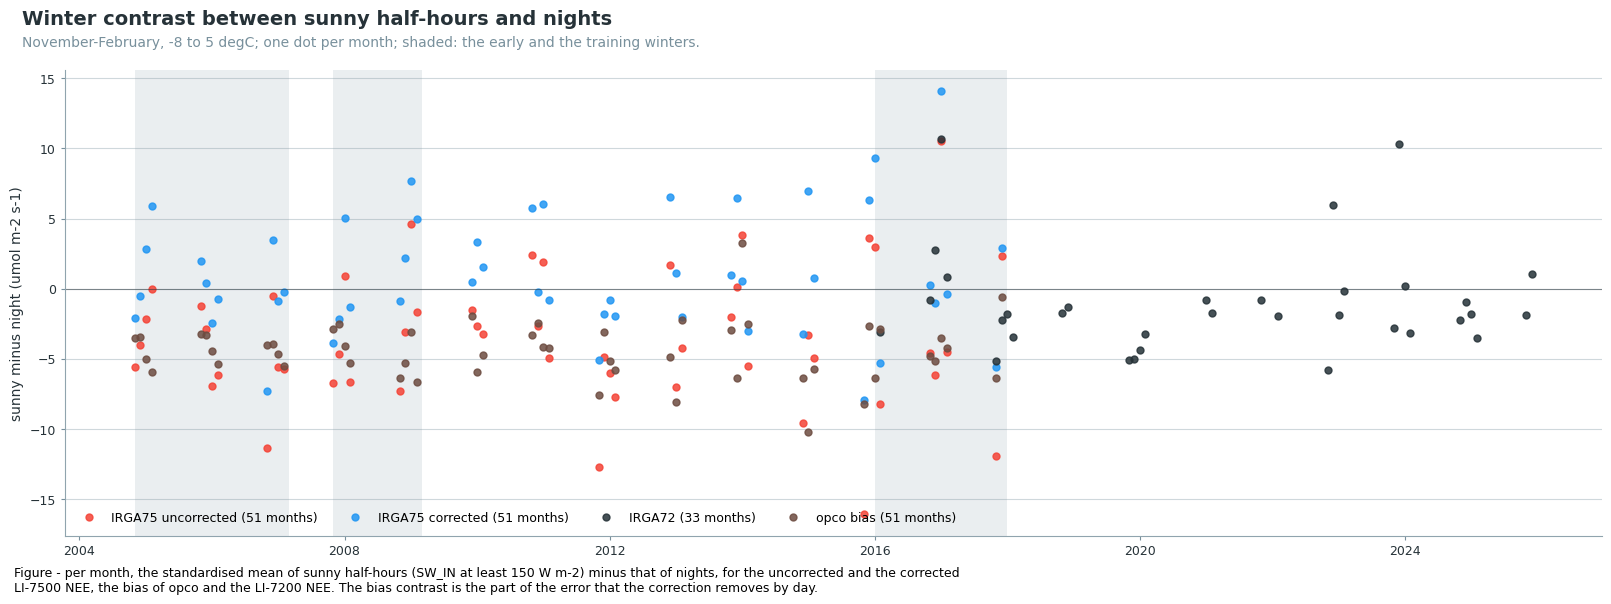

In [32]:
fig, ax = plt.subplots(figsize=(16, 6), layout='constrained')
for _s in ['IRGA75 uncorrected', 'IRGA75 corrected', 'IRGA72', 'opco bias']:
    _d = WC[WC['series'] == _s]
    ax.plot(_d['start'], _d['contrast'], linestyle='none', marker='o', markersize=5, color=SERIES_COLORS[_s],
            alpha=0.85, label=f"{_s} ({len(_d)} months)")
for _a, _b in WINTER_GROUPS.values():
    ax.axvspan(pd.Timestamp(_a), pd.Timestamp(_b), color=cp.MUTED, alpha=0.15, linewidth=0)
ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
ax.set_ylabel('sunny minus night (umol m-2 s-1)')
cp.style_axes(ax)
ax.legend(frameon=False, fontsize=9, loc='lower left', ncol=4)
cp.figure_title(fig, 'Winter contrast between sunny half-hours and nights',
                f'November-February, {WINTER_TA[0]} to {WINTER_TA[1]} degC; one dot per month; '
                'shaded: the early and the training winters.')
figcap(fig, "per month, the standardised mean of sunny half-hours (SW_IN at least 150 W m-2) minus that of nights, "
            "for the uncorrected and the corrected LI-7500 NEE, the bias of opco and the LI-7200 NEE. The bias "
            "contrast is the part of the error that the correction removes by day.")
plt.show()

#### 📋 Table: winter contrast per group of winters

In [33]:
WSUM = WC.groupby(['series', 'group'])['contrast'].agg(['mean', 'std', 'count'])
WSUM['se'] = WSUM['std'] / np.sqrt(WSUM['count'])
tabcap("per series and group of winters, the mean, standard deviation, number and standard error of the monthly "
       "sunny-minus-night contrasts (umol m-2 s-1)")
display(WSUM.round(2))

Table - per series and group of winters, the mean, standard deviation, number and standard error of
the monthly sunny-minus-night contrasts (umol m-2 s-1)



mean   std  count    se
series             group                                           
IRGA72             other winters           -1.47  3.32     26  0.65
                   training winters         0.42  5.22      7  1.97
IRGA75 corrected   other winters            0.86  4.05     23  0.85
                   training winters         1.79  6.85      8  2.42
                   winters 2004/05-2006/07  0.02  3.37     12  0.97
                   winters 2007/08-2008/09  1.46  4.12      8  1.46
IRGA75 uncorrected other winters           -3.72  4.97     23  1.04
                   training winters        -2.46  7.23      8  2.55
                   winters 2004/05-2006/07 -4.35  3.22     12  0.93
                   winters 2007/08-2008/09 -3.07  4.20      8  1.48
opco bias          other winters           -4.58  2.79     23  0.58
                   training winters        -4.25  1.91      8  0.67
                   winters 2004/05-2006/07 -4.36  0.94     12  0.27
                   winters 2007/08-2008/09 -4.53  1.62      8  0.57

#### 📋 Table: scaling factor of the self-heating per group of early winters

In [34]:
_ct = WSUM.loc[('IRGA75 corrected', 'training winters')]
_rows = {}
for _grp in [g for g in WINTER_GROUPS if g != 'training winters']:
    _ce = WSUM.loc[('IRGA75 corrected', _grp)]
    _be = WSUM.loc[('opco bias', _grp), 'mean']
    _d = _ce['mean'] - _ct['mean']
    _se = np.sqrt(_ce['se'] ** 2 + _ct['se'] ** 2)
    _rows[_grp] = {'months': int(_ce['count']), 'corrected contrast minus training': _d, 'its SE': _se,
                   'bias contrast': _be, 's': 1 + _d / _be, 's SE': _se / abs(_be),
                   's 95 % low': 1 + _d / _be - 1.96 * _se / abs(_be),
                   's 95 % high': 1 + _d / _be + 1.96 * _se / abs(_be)}
S_WINTER = pd.DataFrame(_rows).T
tabcap("per group of early winters, the corrected sunny-minus-night contrast minus that of the training winters "
       "(umol m-2 s-1) with its standard error, the bias contrast, and the scaling factor s of the early-year "
       "self-heating that the difference implies, with its standard error and 95 % range")
display(S_WINTER.round(2))

Table - per group of early winters, the corrected sunny-minus-night contrast minus that of the
training winters (umol m-2 s-1) with its standard error, the bias contrast, and the scaling factor s
of the early-year self-heating that the difference implies, with its standard error and 95 % range



,months,corrected contrast minus training,its SE,bias contrast,s,s SE,s 95 % low,s 95 % high
winters 2004/05-2006/07,12.0,-1.77,2.61,-4.36,1.41,0.60,0.23,2.58
winters 2007/08-2008/09,8.0,-0.33,2.83,-4.53,1.07,0.62,-0.15,2.30


## 🛠️ 5 Instrument and setup history

From the documentation pages Instrumentation, Yearly Notes and Level-1 EddyPro settings, the notes
in `workflow/00_L0_CHECKS` and the GIN fieldbook:

- **One LI-7500 throughout.** The setup table lists one LI-7500 (`IRGA75-A`) for every setup period
  from 2004 to 2017. The fieldbook names the head 75H-0640 at CH-LAE in its entries of 2011 and
  2016. It records no exchange of the head between 2004 and 2017; its records before 2011 are a
  legacy fieldbook with gaps, so an exchange before 2011 cannot be fully excluded from the record
  alone.
- **Same position.** The separation from the sonic is N +33, E 0, V -5 cm in all EddyPro runs of
  the LI-7500, and the sonic stays at 47 m and 209°. The fieldbook records no change of the
  inclination of the LI-7500. On 16 December 2010 the head was re-fastened with steel wire instead of
  cable ties.
- **The sonic.** The fieldbook names a Gill HS-100 from 2016; it has no sonic record before 2016,
  and the setup table names an HS-50 there. Whether the sonic was exchanged at the start of 2016 is
  not settled. u* relative to wind speed is about 10 % higher before 2016 (section 1), which a
  change of sonic or of the flow around the boom (the LI-7200 was mounted from January 2016) could
  explain. The ratio of the standard deviation of w to u* and the energy-balance ratio (table
  below) do not change at 2016.
- **Maintenance.** Chemicals were replaced and the analyser calibrated several times (Settings,
  `FIELDBOOK_LI7500`). The CO2 mixing ratio of the LI-7500 (figure below) reads low until the end of
  2007. Extrapolated back from 2008 at the global increase of about 2 ppm per year, the summer
  medians are about 5 ppm low in 2004-2005 and about 20 ppm low in 2006-2007. The record steps up at
  the calibration of December 2007. A calibration error of the concentration changes the flux
  through the gain of the calibration only; a zero offset of this size changes it by a few per
  cent at most. The years with the weakest wind signature of the self-heating (section 4),
  2005-2007, fall into this period; whether the two are connected is not known.
- **Processing.** All LI-7500 runs use the same EddyPro settings and the same lag window
  (0.05-0.75 s); the spectral correction factor of `FC` is 1.03 in every summer.

### 📊 Plot: CO2 mixing ratio of the LI-7500 at midday, per month

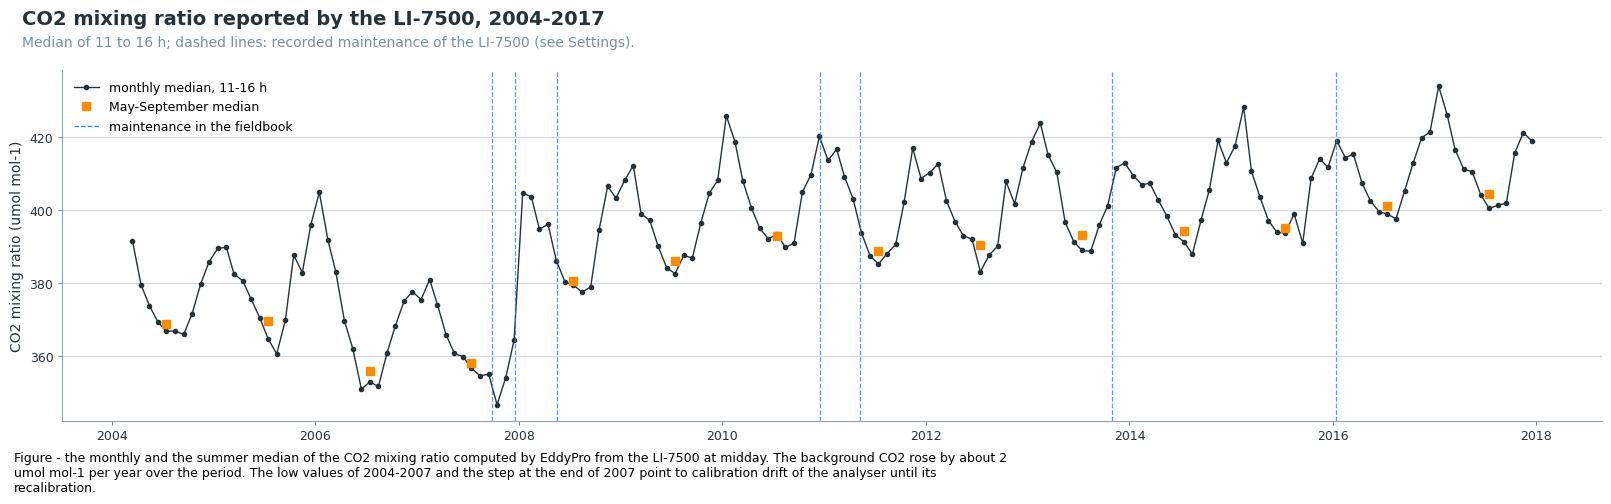

May-September median by year: {2004: 369, 2005: 370, 2006: 356, 2007: 358, 2008: 381, 2009: 386, 2010: 393, 2011: 389, 2012: 390, 2013: 393, 2014: 394, 2015: 395, 2016: 401, 2017: 404}


In [35]:
_x = A[(A.index.hour >= 11) & (A.index.hour <= 15)]
_mm = _x['CO2_MIXING_RATIO'].groupby(_x.index.to_period('M')).median()
_mm.index = _mm.index.to_timestamp() + pd.Timedelta('14D')
_summ = _x[_x['summer']]['CO2_MIXING_RATIO'].groupby(_x[_x['summer']]['year']).median()
fig, ax = plt.subplots(figsize=(16, 5), layout='constrained')
ax.plot(_mm.index, _mm.to_numpy(), color=cp.INK, marker='o', markersize=3, linewidth=1, label='monthly median, 11-16 h')
ax.plot(pd.to_datetime([f"{y}-07-15" for y in _summ.index]), _summ.to_numpy(), color=cp.TEST_COLORS[1],
        marker='s', markersize=6, linestyle='none', label='May-September median')
for _d, _what in FIELDBOOK_LI7500.items():
    ax.axvline(pd.Timestamp(_d), color=cp.TEST_COLORS[3], linewidth=0.9, linestyle='--', alpha=0.8)
ax.plot([], [], color=cp.TEST_COLORS[3], linewidth=0.9, linestyle='--', label='maintenance in the fieldbook')
ax.set_ylabel('CO2 mixing ratio (umol mol-1)')
cp.style_axes(ax)
ax.legend(frameon=False, fontsize=9, loc='upper left')
cp.figure_title(fig, 'CO2 mixing ratio reported by the LI-7500, 2004-2017',
                'Median of 11 to 16 h; dashed lines: recorded maintenance of the LI-7500 (see Settings).')
figcap(fig, "the monthly and the summer median of the CO2 mixing ratio computed by EddyPro from the LI-7500 at midday. "
            "The background CO2 rose by about 2 umol mol-1 per year over the period. The low values of 2004-2007 "
            "and the step at the end of 2007 point to calibration drift of the analyser until its recalibration.")
plt.show()
print("May-September median by year:", _summ.round(0).astype(int).to_dict())

### 📋 Table: energy-balance ratio and turbulence statistics, summer midday

In [36]:
def turbulence_table(d, name):
    s = d[d.index.month.isin((6, 7, 8)) & (d['sw'] > 200) & d['sw_meas'] & (d['LE_SSITC_TEST'] <= 1)
          & (d['H_SSITC_TEST'] <= 1)].dropna(subset=['LE', 'H', 'rn'])
    g = s.groupby('year')
    return pd.DataFrame({'analyser': name, 'records': g.size(),
                         '(H + LE) / Rn': g.apply(lambda q: (q['LE'].sum() + q['H'].sum()) / q['rn'].sum()),
                         'H / Rn': g.apply(lambda q: q['H'].sum() / q['rn'].sum()),
                         'sigma_w / u*': g.apply(lambda q: (q['W_SIGMA'] / q['USTAR']).median()),
                         'u* / U': g['ust_u'].median()})


TURB = pd.concat([turbulence_table(A, 'IRGA75'), turbulence_table(B, 'IRGA72')]).set_index('analyser', append=True)
tabcap("per year and analyser, June-August, SW_IN above 200 W m-2 (measured), H and LE with SSITC flag 0 or 1: the "
       "energy-balance ratio (H + LE) / Rn and H / Rn (sums), and the medians of sigma_w / u* and u* / U. Rn is computed "
       "from the four radiation components; the ground heat flux and storage are not included. Before September "
       "2005 no measured radiation is available")
display(TURB.round(3))

Table - per year and analyser, June-August, SW_IN above 200 W m-2 (measured), H and LE with SSITC
flag 0 or 1: the energy-balance ratio (H + LE) / Rn and H / Rn (sums), and the medians of sigma_w /
u* and u* / U. Rn is computed from the four radiation components; the ground heat flux and storage
are not included. Before September 2005 no measured radiation is available



,,records,(H + LE) / Rn,H / Rn,sigma_w / u*,u* / U
year,analyser,,,,,
2006,IRGA75,1447,0.847,0.373,1.375,0.296
2007,IRGA75,1321,0.895,0.329,1.347,0.271
2008,IRGA75,1418,1.090,0.358,1.339,0.281
2009,IRGA75,1333,1.053,0.340,1.370,0.277
2010,IRGA75,1158,1.100,0.310,1.390,0.279
2011,IRGA75,1287,0.966,0.376,1.352,0.269
2012,IRGA75,1176,0.954,0.318,1.349,0.267
2013,IRGA75,1267,0.857,0.341,1.353,0.303
2014,IRGA75,1433,0.890,0.332,1.398,0.286


## 🌳 6 Weather and footprint of the early summers

The standardised comparisons remove the effect of light and temperature on a given day, but not
that of soil water, of the weather of the year before or of the state of the stand. The table puts
the summer weather next to the summer daytime residual of section 3.

### 📋 Table: summer weather per year and the summer daytime residual

In [37]:
_m = met.loc[:IRGA72_LAST]
_s = _m[_m.index.month.isin(SUMMER)]
_d = _s[_s['ppfd_meas'] & (_s['ppfd'] > DAY_PPFD)]
WEATHER = pd.DataFrame({'TA mean': _s['ta'].groupby(_s.index.year).mean(),
                        'VPD daytime mean': _d['vpd'].groupby(_d.index.year).mean(),
                        'PPFD daytime mean': _d['ppfd'].groupby(_d.index.year).mean(),
                        'SWC 0.1 m mean': _s['swc10'].groupby(_s.index.year).mean(),
                        'SWC 0.3 m mean': _s['swc30'].groupby(_s.index.year).mean(),
                        'SWC 0.1 m p05': _s['swc10'].groupby(_s.index.year).quantile(0.05)})
WEATHER = WEATHER.join(RESID_DAY.rename(columns=lambda c: f"residual {c}"))
tabcap("per year, May-September: mean air temperature (degC), mean daytime VPD (kPa) and PPFD (umol m-2 s-1, measured), "
       "mean and 5th percentile of the homogenised soil water content (% VWC), and the summer daytime residual of each "
       "series against the model of the LI-7200 years (section 3)")
display(WEATHER.round(2))

Table - per year, May-September: mean air temperature (degC), mean daytime VPD (kPa) and PPFD (umol
m-2 s-1, measured), mean and 5th percentile of the homogenised soil water content (% VWC), and the
summer daytime residual of each series against the model of the LI-7200 years (section 3)



,TA mean,VPD daytime mean,PPFD daytime mean,SWC 0.1 m mean,SWC 0.3 m mean,SWC 0.1 m p05,residual IRGA75 uncorrected,residual IRGA75 corrected,residual IRGA72
TIMESTAMP_MIDDLE,,,,,,,,,
2004,15.53,0.16,366.70,21.24,18.51,13.83,NaN,NaN,NaN
2005,16.01,0.64,768.45,23.24,22.75,19.06,1.03,3.72,NaN
2006,16.52,0.67,758.59,24.28,22.71,17.55,1.31,3.75,NaN
2007,15.18,0.53,737.44,27.44,24.86,22.82,0.06,2.46,NaN
2008,15.49,0.57,774.40,27.56,25.16,21.47,-0.63,2.20,NaN
2009,16.64,0.61,796.43,26.05,23.34,21.22,-0.49,2.28,NaN
2010,15.18,0.53,712.14,28.37,26.63,21.47,-1.43,1.41,NaN
2011,16.42,0.66,814.18,27.12,24.78,22.50,-2.19,0.51,NaN
2012,16.06,0.57,783.46,30.52,26.14,24.43,-1.50,1.22,NaN


### 📋 Table: summer daytime residual by wind sector

In [38]:
_ld = LD[LD['series'].isin(['IRGA75 corrected', 'IRGA72'])].dropna(subset=['ppfd', 'ta', 'vpd', 'doy']).copy()
_ld['wd'] = np.where(_ld['series'] == 'IRGA72', B['WD'].reindex(_ld.index).to_numpy(), A['WD'].reindex(_ld.index).to_numpy())
_ld['residual'] = _ld['value'] - REFMODEL.predict(_ld[['ppfd', 'ta', 'vpd', 'doy']])
_ld['sector'] = pd.cut(_ld['wd'], [0, 90, 180, 270, 360], labels=['N-E', 'E-S', 'S-W', 'W-N'])
_ld['group'] = _ld['series'].str.replace(' corrected', '') + ' ' + _ld['period'].astype(str)
SECTOR = _ld.groupby(['group', 'sector'], observed=True)['residual'].mean().unstack()
_share = _ld.groupby(['group', 'sector'], observed=True).size().unstack()
SECTOR = SECTOR.join((100 * _share.div(_share.sum(axis=1), axis=0)).add_suffix(' %'))
tabcap("per analyser and period, the mean summer daytime residual (umol m-2 s-1) of the corrected LI-7500 NEE and the "
       "LI-7200 NEE against the model of the LI-7200 years, per wind sector (degrees from north), and the share of the "
       "records in each sector (%)")
display(SECTOR.round(2))

Table - per analyser and period, the mean summer daytime residual (umol m-2 s-1) of the corrected
LI-7500 NEE and the LI-7200 NEE against the model of the LI-7200 years, per wind sector (degrees
from north), and the share of the records in each sector (%)



sector,N-E,E-S,S-W,W-N,N-E %,E-S %,S-W %,W-N %
group,,,,,,,,
IRGA72 2016-2017,0.41,1.51,-0.20,0.44,5.20,17.54,70.71,6.55
IRGA72 2018-2025,0.97,0.19,-0.35,-0.28,10.46,30.87,54.25,4.42
IRGA75 2005-2009,1.91,3.40,2.95,0.70,10.07,29.29,56.02,4.62
IRGA75 2010-2015,1.35,2.14,0.45,0.17,9.07,29.07,58.06,3.80
IRGA75 2016-2017,0.40,1.45,0.04,0.51,5.73,20.78,68.37,5.12


## 📐 7 Implied adjustment of the early summers

The summer daytime correction of a year is estimated as the monthly mean bias of the summer daytime
records that pass all tests, times the number of daytime half-hours of that month (SW_IN above
12 W m-2), summed over May to September. A scaling factor `s` of the early-year correction changes
the May-September `NEE` by `(1 - s)` times the summed bias (negative: more uptake).

- **Scenario A, from the evidence of section 4:** `s` from the summer wind-speed test of each group
  of years (2005-2007, 2008-2009), limited to 0 to 1, with its 95 % range. The winter test is not
  used: its uncertainty is too large to constrain `s`.
- **Scenario B, an assumption:** the ecosystem of 2005-2009 responded to light and temperature as
  in 2016-2025. `s` is then the value that brings the standardised corrected flux of each year to
  the target of section 3, `s = 1 - gap / |bias|`, limited to 0 to 1. Where `s` would have to be
  below 0, even the uncorrected flux shows less uptake than the target, and no size of the
  correction closes the gap.

### 📋 Table: implied change of the May-September NEE, 2005-2009

In [39]:
_day = A['summer'] & (A[SW_OPCO] > DAY_SW)
_mb = A.loc[_day & Q75, 'BIAS_OPCO'].groupby([A.loc[_day & Q75, 'year'], A.loc[_day & Q75].index.month]).mean()
_nh = _day.groupby([A['year'], A.index.month]).sum()
BIAS_SUM = (_mb * _nh.reindex(_mb.index)).groupby(level=0).sum() * GC_PER_HALFHOUR   # gC m-2, negative

_grp_of = {y: g for g, (y0, y1) in WIND_GROUPS.items() for y in range(y0, y1 + 1)}
_rows = []
for _y in range(EARLY[0], EARLY[1] + 1):
    _sa = S_WIND.loc[_grp_of[_y]]
    _s_a = float(np.clip(_sa['s'], 0, 1))
    _s_lo, _s_hi = float(np.clip(_sa['s 95 % low'], 0, 1)), float(np.clip(_sa['s 95 % high'], 0, 1))
    _gap = YEAR_DAY.loc[_y, 'IRGA75 corrected'] - TARGET
    _b = YEAR_DAY.loc[_y, 'opco bias']
    _s_raw = 1 - _gap / abs(_b)
    _s_b = float(np.clip(_s_raw, 0, 1))
    _rows.append({'year': _y, 'summer daytime bias sum gC': BIAS_SUM[_y],
                  'A: s': _s_a, 'A: change gC': (1 - _s_a) * BIAS_SUM[_y],
                  'A: change at upper s gC': (1 - _s_hi) * BIAS_SUM[_y],
                  'A: change at lower s gC': (1 - _s_lo) * BIAS_SUM[_y],
                  'B: gap to target': _gap, 'B: s unbounded': _s_raw, 'B: s': _s_b,
                  'B: change gC': (1 - _s_b) * BIAS_SUM[_y],
                  'B: gap left at s = 0': max(_gap - abs(_b), 0)})
IMPLIED = pd.DataFrame(_rows).set_index('year')
IMPLIED.loc['2005-2009 mean'] = IMPLIED.mean()
IMPLIED = IMPLIED + 0.0   # no negative zeros in the display
tabcap(f"per early year, the summed summer daytime bias (gC m-2), the scaling factor and the change of the "
       f"May-September NEE in scenario A (s from the wind test of the group of the year, with the change at the "
       f"limits of its 95 % range) and in scenario B (gap of the standardised corrected NEE to the "
       f"target {TARGET:.2f} umol m-2 s-1, the scaling factor without and with the limits 0 to 1, the change, and the gap "
       "that remains at s = 0, umol m-2 s-1). Negative changes are more uptake")
display(IMPLIED.round(2))

Table - per early year, the summed summer daytime bias (gC m-2), the scaling factor and the change
of the May-September NEE in scenario A (s from the wind test of the group of the year, with the
change at the limits of its 95 % range) and in scenario B (gap of the standardised corrected NEE to
the target -9.24 umol m-2 s-1, the scaling factor without and with the limits 0 to 1, the change,
and the gap that remains at s = 0, umol m-2 s-1). Negative changes are more uptake



,summer daytime bias sum gC,A: s,A: change gC,A: change at upper s gC,A: change at lower s gC,B: gap to target,B: s unbounded,B: s,B: change gC,B: gap left at s = 0
year,,,,,,,,,,
2005,-243.61,0.20,-194.60,0.0,-243.61,2.14,0.05,0.05,-231.29,0.00
2006,-222.41,0.20,-177.66,0.0,-222.41,2.73,-0.29,0.00,-222.41,0.61
2007,-214.65,0.20,-171.47,0.0,-214.65,0.91,0.53,0.53,-99.91,0.00
2008,-254.76,1.00,0.00,0.0,-201.39,1.03,0.57,0.57,-110.67,0.00
2009,-250.63,1.00,0.00,0.0,-198.12,1.21,0.49,0.49,-128.03,0.00
2005-2009 mean,-237.21,0.52,-108.74,0.0,-216.04,1.60,0.27,0.33,-158.46,0.12


## 📝 Findings

All numbers refer to May-September and, unless stated otherwise, to daytime.

**1. The early years lie within the training conditions.** Per driver, at most 1.1 % of the summer
daytime records of 2005-2015 lie outside the 0.1-99.9 % range of 2016-2017; opco flags 0.9 % of
2005-2009 as outside its envelope (0.8 % in 2016-2017). The drivers that differ are u* relative to
wind speed (median 0.28 against 0.25) and the CO2 density of the LI-7500 (14.0 against
15.1 mmol m-3).

**2. The correction is not larger in the early years under the same conditions.** Standardised to
the same light and temperature, the bias is -2.23 umol m-2 s-1 in 2005-2009 and -2.16 in
2016-2017 (ratio 1.03). The heating term is 5 % larger, from a 14 % larger u*²/U and an 8 % lower
CO2 density, and ξ is 5 % smaller. Refitting opco on 2016 alone or 2017 alone changes the bias of
2005-2009 by no more than 0.02 umol m-2 s-1 (-2.75 and -2.77 against -2.75 with both years), and
each of these models corrects the other training year to within 0.05 umol m-2 s-1 of the LI-7200
(ratio of sums 0.996 and 1.000). On the common records
of the overlap summers the uncorrected LI-7500 shows 19 % more uptake than the LI-7200, the
corrected one 0.3 %.

**3. The difference sits in the uncorrected flux and is concentrated in 2005-2007.** The
standardised corrected `NEE` is -7.1 (2005), -6.5 (2006), -8.3 (2007), -8.2 (2008) and -8.0
(2009) umol m-2 s-1, -8.7 to -9.4 in 2010-2015, against -9.87 (range -8.6 to -11.8) in the
LI-7200 years 2016-2025. Allowing for the record selection of the LI-7500 (+0.63), the gap to the
LI-7200 years is +2.1, +2.7, +0.9, +1.0 and +1.2 in 2005-2009 and +0.17 in 2010-2015. Since the
correction is about the same in every year (-2.0 to -2.5), the same pattern is in the uncorrected
flux. In 2005 and 2006 even the uncorrected flux is near (2005, -9.36) or above (2006, -8.63) the
target of -9.24: no size of the correction closes the gap of 2006. A model of the LI-7200 years
with VPD and day of year gives the same pattern. Summer nights agree: the corrected LI-7500 of
2005-2009 has +4.91 umol m-2 s-1 at standardised temperature, the LI-7200 years +4.99.

**4. The LI-7500 tests disagree for 2005-2007 and agree for 2008-2009.**

- *Wind signature (summer).* The bias is more negative at low wind. On the common records of the
  overlap the true bias has a wind contrast of +1.77 and +2.12 umol m-2 s-1, opco +1.72 and +1.88.
  In the uncorrected flux this contrast is +0.67, +0.13 and +0.32 in 2005-2007, against +0.9 to
  +2.5 in 2008-2017. The implied scaling of the self-heating is s = 0.20 ± 0.44 (1 SE, from the
  year-to-year spread of the LI-7200 years) for 2005-2007, 1.13 ± 0.47 for 2008-2009 and 1.06 for
  2010-2015. The 2005-2007 value lies 1.8 standard errors below 1 with the spread of the LI-7200
  years and 3.2 with the smaller spread of the LI-7500 reference years 2010-2017.
- *Sunny days against nights (winter).* In the winters 2004/05-2006/07 the uncorrected flux shows a
  sunny-day contrast of -5.1 umol m-2 s-1 against a bias contrast of -4.4: s = 1.49 ± 0.58, which
  excludes s below 0.36. For 2007/08-2008/09, s = 1.10 ± 0.61.

A uniformly weaker self-heating in 2005-2007 would show in both tests. It shows only in the summer
wind signature.

**5. Instrument history.** One LI-7500 head (75H-0640 in the fieldbook of 2011 and 2016) at the same
position throughout; no recorded change of inclination; the same EddyPro settings. The analyser
reported CO2 about 5 ppm (2004-2005) and about 20 ppm (2006-2007) too low until its recalibration
in December 2007. The energy-balance ratio (0.85 to 1.10 in 2006-2015, 0.84 to 0.91 for the
LI-7200 years) and sigma_w / u* (1.34 to 1.44) show no change of the turbulence measurement.

**6. Weather and footprint.** Soils were drier in the summers of 2004-2006 (0.3 m: 18.5 to 22.7 %
VWC, 23 to 27 % in 2007-2017), but the dry LI-7200 summers 2018 and 2022 (22.0 and 23.0 %) have residuals
of only +0.3 and +0.9 umol m-2 s-1. The early deficit appears in every wind sector, and the sector
shares did not change.

**7. Implied adjustment.** The summer daytime bias sums to -215 to -255 gC m-2 per year in
2005-2009.

- *Scenario A (wind test):* for 2005-2007, s = 0.20 changes the May-September `NEE` by -171 to
  -195 gC m-2 per year (95 % range 0 to -244); for 2008-2009 there is no change (range 0 to
  -201). Mean over 2005-2009: -109 gC m-2 (range 0 to -216).
- *Scenario B (assumption: the ecosystem of 2005-2009 as in 2016-2025):* -158 gC m-2 per year on
  average, with s = 0.05 in 2005 and 0 in 2006. This is an upper bound; for 2006 it would require
  the removal of the whole correction and still leave 0.6 umol m-2 s-1.

**Answer to the open question.** The correction transfers to the early years as a model: the
drivers are within the training range, the bias under matched conditions is the same, and the
transfer between the two training years is near perfect. For 2008-2009, and 2010-2015, the LI-7500
itself shows a self-heating of the training size, and the remaining summer gap (about
1 umol m-2 s-1 in 2008-2009) lies within the year-to-year spread of the LI-7200 years (sd 1.2);
there it is most likely real variability. For 2005-2007 the question is not settled. The summer
wind signature indicates a self-heating about 80 % weaker, which would make the correction too
large by about 170 to 195 gC m-2 per summer. The winter test of the same years does not support
this, and in 2005-2006 part of the deficit is present even without any correction. The difference
of about 120 gC m-2 in the 2005-2009 means is therefore concentrated in 2005-2007 and of unresolved
cause: an oversized correction in these three summers is possible, and of the right size, but not
demonstrated.

**Caveats.** The wind test assumes the same wind dependence of the ecosystem flux in every year; a
drier canopy in 2005-2006 may not satisfy this. Scenario A assumes that the bias scales as a whole.
The sums are estimated from the monthly mean bias times the number of daytime half-hours, not from
gap-filled series. The LI-7200 years include their own extremes, and the light sensors drift by a
few per cent over the record.

***

# End of notebook.

In [40]:
NOTEBOOK_END = datetime.now()
_h, _rem = divmod(int((NOTEBOOK_END - NOTEBOOK_START).total_seconds()), 3600)
_m, _s = divmod(_rem, 60)

print(f"Started:  {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Finished: {NOTEBOOK_END.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Runtime:  {_h:02d}:{_m:02d}:{_s:02d} (hh:mm:ss)")

Started:  2026-10-30 19:30:09
Finished: 2026-10-30 19:30:31
Runtime:  00:00:22 (hh:mm:ss)
